# CONTROL / Territories and networks
A critical atlas of IPv4 geolocation and corporate networks.

Global geolocation studies retain their point patterns. Country-level and corporate maps use thin geographic boundaries and colored discrete plus signs. Plus-sign color encodes the national value; marker spacing is constant and carries no additional quantity. Unmarked anthracite means zero within the selected dataset, medium grey means no geolocation denominator.

A fine geographic graticule, registration marks and Roboto Light give the atlas a scientific plate layout. All pages use an anthracite background, 17 × 11 inches landscape. Estimated geolocation, observed BGP routing and legal ownership are distinct. Primary corporate organizations may omit subsidiaries; official provider lists have different scopes. CAIDA snapshot: 1 October 2026. The IP2Location snapshot date remains unverified.

## Chapter 1 / Setup
Import dependencies once, define local paths, and establish one visual language for the atlas.

In [1]:
from pathlib import Path
from collections import defaultdict
import gzip
import heapq
import ipaddress
import json
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import contains_xy
from shapely.geometry import LineString
from matplotlib import font_manager
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, PowerNorm, LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

PROJECT_DIR = Path("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignement 03 Spatial Relatedness")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PAGE_SIZE = (17, 11)
BACKGROUND = "#25282b"
CMAP = LinearSegmentedColormap.from_list(
    "atlas_light", ["#b295ff", "#858dff", "#38cddd", "#59e3ac", "#f2ed86"])
COMPANIES = ["Amazon", "Meta", "Google", "Microsoft"]
SERVICES = ["Google", "Google Cloud", "AWS", "Azure Public"]
PDF_FILES = []
# Register a local Roboto Light font; no system font installation is needed.
font_manager.fontManager.addfont(DATA_DIR / "fonts" / "Roboto-Light.ttf")
plt.rcParams.update({"figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
                     "savefig.facecolor": BACKGROUND, "text.color": "#e4e6e8", "axes.labelcolor": "#c5cbd0", "xtick.color": "#c5cbd0", "ytick.color": "#c5cbd0", "font.family": "Roboto", "font.weight": "light", "axes.labelweight": "light",
                     "font.size": 10, "pdf.fonttype": 42, "hatch.linewidth": 0.32})
atlas = PdfPages(OUTPUT_DIR / "Control_Internet_Atlas.pdf")

In [2]:
# Shared graphic system: geographic screen, registration marks and light typography.
boundary_path = DATA_DIR / "naturalearth_countries_50m.geojson"
world = gpd.read_file(boundary_path)
world["country_code"] = world["ISO_A2_EH"]
missing = world["country_code"].isna() | world["country_code"].isin(["", "-99"])
world.loc[missing, "country_code"] = world.loc[missing, "ISO_A2"]
world = world.loc[world["ADMIN"].ne("Antarctica")].to_crs("ESRI:54030")
world["geometry"] = world.geometry.simplify(12000, preserve_topology=True)

# Build the graticule once, in geographic and Robinson coordinates.
grid_lines = []
for longitude in range(-180, 181, 15):
    grid_lines.append(LineString([(longitude, latitude) for latitude in np.linspace(-60, 85, 90)]))
for latitude in np.arange(-60, 86, 7.5):
    grid_lines.append(LineString([(longitude, latitude) for longitude in np.linspace(-180, 180, 180)]))
geographic_grid = gpd.GeoSeries(grid_lines, crs="EPSG:4326")
projected_grid = geographic_grid.to_crs("ESRI:54030")


def registration_marks(ax):
    for x, y in [(0, 0), (0, 1), (1, 0), (1, 1)]:
        dx = 0.018 if x == 0 else -0.018
        dy = 0.035 if y == 0 else -0.035
        ax.plot([x, x + dx], [y, y], transform=ax.transAxes,
                color="#919fa9", linewidth=0.4, clip_on=False)
        ax.plot([x, x], [y, y + dy], transform=ax.transAxes,
                color="#919fa9", linewidth=0.4, clip_on=False)


def draw_grid(ax, projected=True):
    grid = projected_grid if projected else geographic_grid
    for line in grid:
        ax.plot(*line.xy, color="#607f87", linewidth=0.22,
                linestyle=(0, (1, 3)), alpha=0.45, zorder=3)
    registration_marks(ax)


def prepare_axis(ax):
    ax.set(xlim=(-180, 180), ylim=(-65, 85), aspect="equal")
    ax.set_axis_off()


def draw_points(ax, points, value=None, norm=None, size=None, color="#443983"):
    prepare_axis(ax)
    if size is None:
        size = float(np.clip(9 * np.sqrt(300 / max(len(points), 1)), 0.8, 18))
    options = {"c": color} if value is None else {
        "c": points[value].astype(float), "cmap": CMAP, "norm": norm}
    ax.scatter(points["longitude"], points["latitude"], s=size,
               linewidths=0, alpha=0.95, rasterized=True, zorder=2, **options)
    draw_grid(ax, projected=False)


def page(title, subtitle):
    fig = plt.figure(figsize=PAGE_SIZE)
    ax = fig.add_axes([0.055, 0.22, 0.89, 0.61])
    fig.text(0.045, 0.905, title, fontsize=27, fontweight="light", color="#e6e8ea")
    fig.text(0.047, 0.865, subtitle, fontsize=10, color="#afb8c1")
    return fig, ax


def add_scale(fig, norm, label, panel=False):
    position = [0.33, 0.14, 0.34, 0.009]
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP),
                      cax=fig.add_axes(position), orientation="horizontal")
    if isinstance(norm, PowerNorm):
        bar.set_ticks([0, 0.01, 0.1, 1, 10, 100])
        bar.set_ticklabels(["0", "0.01", "0.1", "1", "10", "100"])
    bar.set_label(label, fontsize=8, labelpad=6, color="#c9d0d6")
    bar.ax.tick_params(labelsize=7, length=2, width=0.4, colors="#c9d0d6")
    bar.outline.set_visible(False)


def export_page(fig, filename, note):
    number = len(PDF_FILES) + 1
    fig.text(0.045, 0.968, "C O N T R O L   /   NETWORK TERRITORIES", fontsize=8, color="#c3cbd2")
    fig.text(0.955, 0.968, f"RESEARCH ATLAS     /     PLATE {number:02d}",
             ha="right", fontsize=8, color="#c3cbd2")
    for y in [0.952, 0.092]:
        fig.add_artist(plt.Line2D([0.045, 0.955], [y, y], transform=fig.transFigure,
                                 color="#66717b", linewidth=0.4))
    fig.text(0.045, 0.074, "METHOD / SOURCE NOTES", fontsize=6.8, color="#b4bec7")
    fig.text(0.045, 0.038, note, fontsize=7.5, color="#b4bec7", linespacing=1.5)
    fig.text(0.955, 0.017, f"IPv4  /  SPATIAL RELATEDNESS                                      {number:02d}",
             fontsize=6.8, color="#b4bec7", ha="right")
    # Keep the exact landscape page size; never crop the PDF.
    fig.savefig(OUTPUT_DIR / filename, format="pdf", dpi=300, facecolor=BACKGROUND)
    atlas.savefig(fig, dpi=300, facecolor=BACKGROUND)
    PDF_FILES.append(filename)
    plt.show()
    plt.close(fig)


def draw_countries(ax, values, value, norm):
    mapped = world.merge(values[["country_code", value]], on="country_code",
                         how="left", validate="many_to_one")
    mapped.plot(ax=ax, facecolor="#3b3f44", edgecolor="none")
    known = mapped.loc[mapped[value].notna()]
    if not known.empty:
        known.plot(ax=ax, facecolor=BACKGROUND, edgecolor="none")
    positive = mapped.loc[mapped[value].gt(0)]
    colors = plt.get_cmap(CMAP)(norm(positive[value].to_numpy(dtype=float)))
    # Place discrete plus signs on one fixed lattice, clipped to each country.
    # Marker density is decorative and constant; color alone encodes the value.
    step = 105000
    marker_size = 3 if ax.get_position().width > 0.6 else 1.0
    for geometry, color in zip(positive.geometry, colors):
        xmin, ymin, xmax, ymax = geometry.bounds
        xs = np.arange(np.floor(xmin / step) * step, xmax + step, step)
        ys = np.arange(np.floor(ymin / step) * step, ymax + step, step)
        x, y = np.meshgrid(xs, ys)
        inside = contains_xy(geometry, x.ravel(), y.ravel())
        x, y = x.ravel()[inside], y.ravel()[inside]
        if len(x) == 0:
            point = geometry.representative_point()
            x, y = [point.x], [point.y]
        ax.scatter(x, y, marker="+", s=marker_size, linewidths=0.3,
                   color=color, zorder=2)
    mapped.boundary.plot(ax=ax, color="#9da7b1", linewidth=0.32)
    draw_grid(ax)
    xmin, ymin, xmax, ymax = world.total_bounds
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal")
    ax.set_axis_off()
    unmatched = values.loc[~values["country_code"].isin(world["country_code"]), "country_code"]
    if len(unmatched):
        print("Codes without a matching polygon:", sorted(unmatched.unique().tolist()))


def country_panel(tables, labels, value, norm, title, subtitle, filename, note, scale_label):
    fig, axes = plt.subplots(2, 2, figsize=PAGE_SIZE)
    fig.subplots_adjust(left=0.055, right=0.945, bottom=0.235, top=0.81,
                        hspace=0.24, wspace=0.07)
    for i, (ax, label) in enumerate(zip(axes.flat, labels)):
        draw_countries(ax, tables[label], value, norm)
        ax.set_title(f"{chr(65 + i)}   /   {label}", fontsize=12, fontweight="light", loc="left", pad=7)
    fig.text(0.045, 0.905, title, fontsize=26, fontweight="light", color="#e6e8ea")
    fig.text(0.047, 0.865, subtitle, fontsize=10, color="#afb8c1")
    add_scale(fig, norm, scale_label, panel=True)
    export_page(fig, filename, note)


## Chapter 2 / The planetary pattern
Read the geolocation intervals once. Count addresses rather than records, and aggregate coincident points. Exclude unknown countries from mapped totals; preserve country codes such as NA (Namibia).

In [3]:
# Load one source table for all subsequent spatial comparisons.
columns = ["ip_start", "ip_end", "country_code", "country", "region",
           "city", "latitude", "longitude", "postal_code", "time_zone"]
geo = pd.read_csv(DATA_DIR / "IP2LOCATION-LITE-DB11.CSV", header=None,
                  names=columns, keep_default_na=False,
                  dtype={"ip_start": "int64", "ip_end": "int64"})
geo = geo.sort_values("ip_start").reset_index(drop=True)
for field in ["latitude", "longitude"]:
    geo[field] = pd.to_numeric(geo[field], errors="coerce")
geo["ip_count"] = geo["ip_end"] - geo["ip_start"] + 1
assert geo["ip_count"].gt(0).all()
assert (geo["ip_start"].to_numpy()[1:] > geo["ip_end"].to_numpy()[:-1]).all()
known_country = ~geo["country_code"].isin(["", "-"])
valid_coordinates = geo["latitude"].between(-90, 90) & geo["longitude"].between(-180, 180)
map_data = geo.loc[known_country & valid_coordinates]
locations = map_data.groupby(["latitude", "longitude"], as_index=False).agg(
    ip_count=("ip_count", "sum"), interval_count=("ip_start", "size"))
country_locations = map_data.groupby(
    ["country_code", "latitude", "longitude"], as_index=False
).agg(ip_count=("ip_count", "sum"))
country_counts = geo.loc[known_country].groupby(
    ["country_code", "country"], as_index=False
)["ip_count"].sum().rename(columns={"ip_count": "ipv4_count", "country": "country_name"})
country_counts.to_csv(OUTPUT_DIR / "ipv4_totals_by_country.csv", index=False)

city_data = map_data.loc[~map_data["region"].isin(["", "-"]) & ~map_data["city"].isin(["", "-"])]
cities = city_data.groupby(["country", "region", "city"], as_index=False).agg(
    ip_count=("ip_count", "sum"), interval_count=("ip_start", "size"),
    latitude=("latitude", "median"), longitude=("longitude", "median"))
cities.to_json(OUTPUT_DIR / "cities.json", orient="records", force_ascii=False)
print(f"Geolocation intervals: {len(geo):,}; mapped locations: {len(locations):,}")

Geolocation intervals: 2,996,774; mapped locations: 86,800


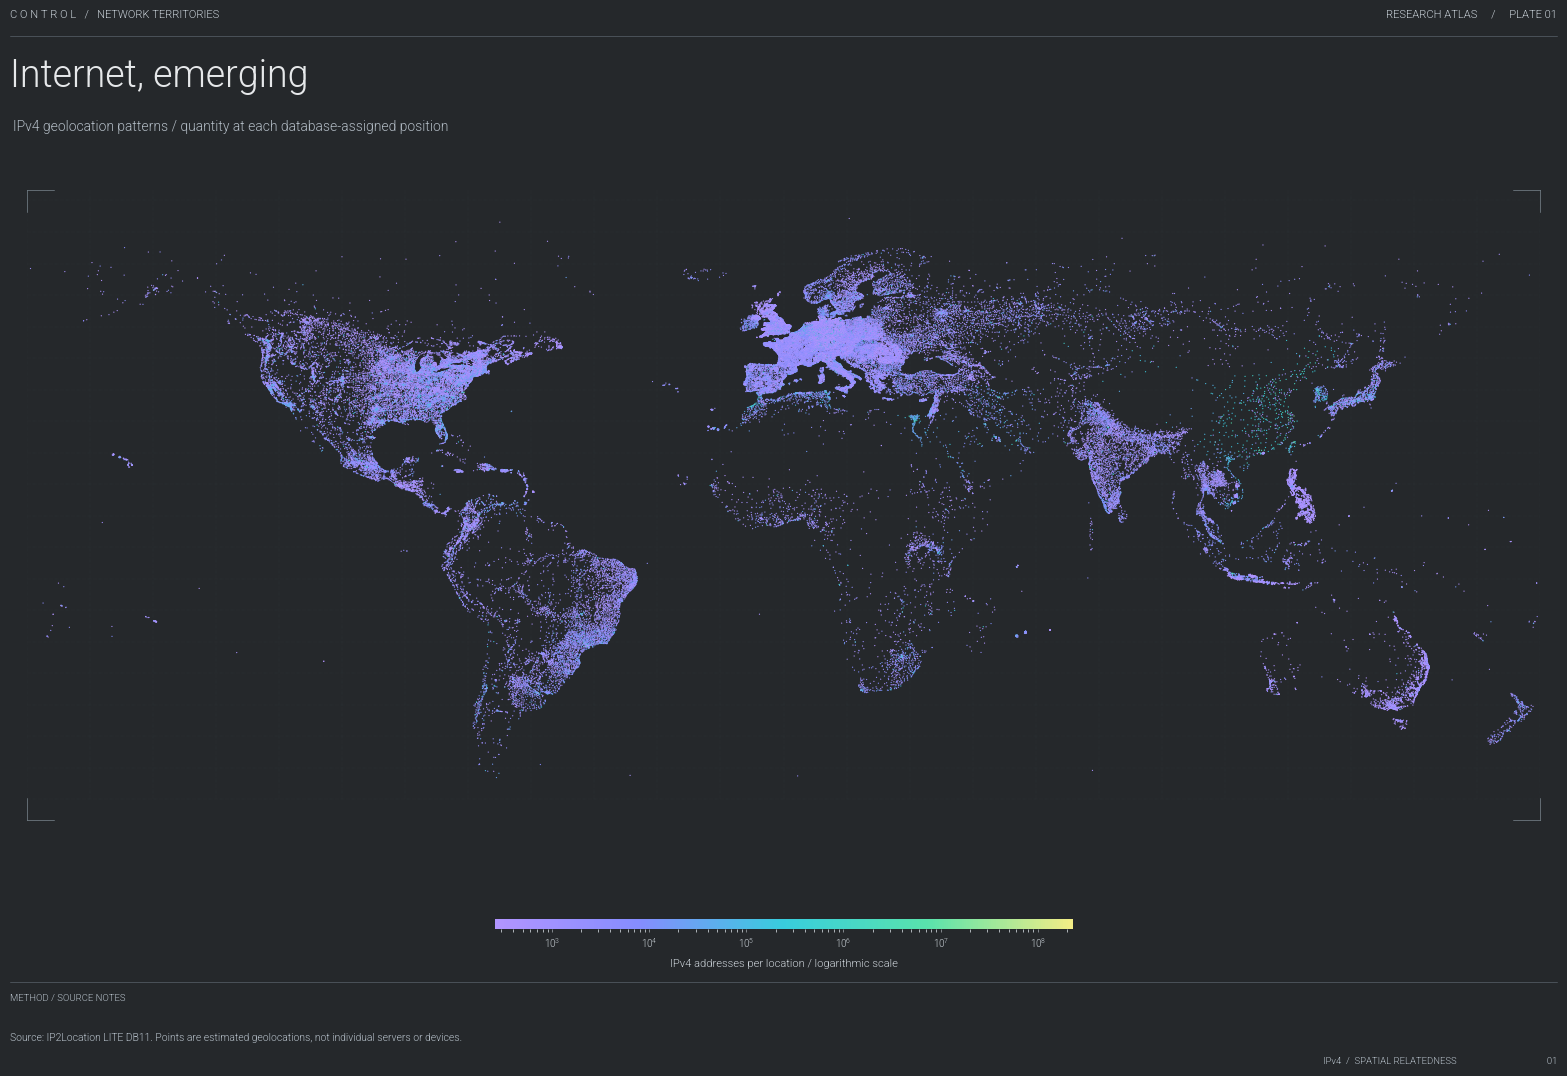

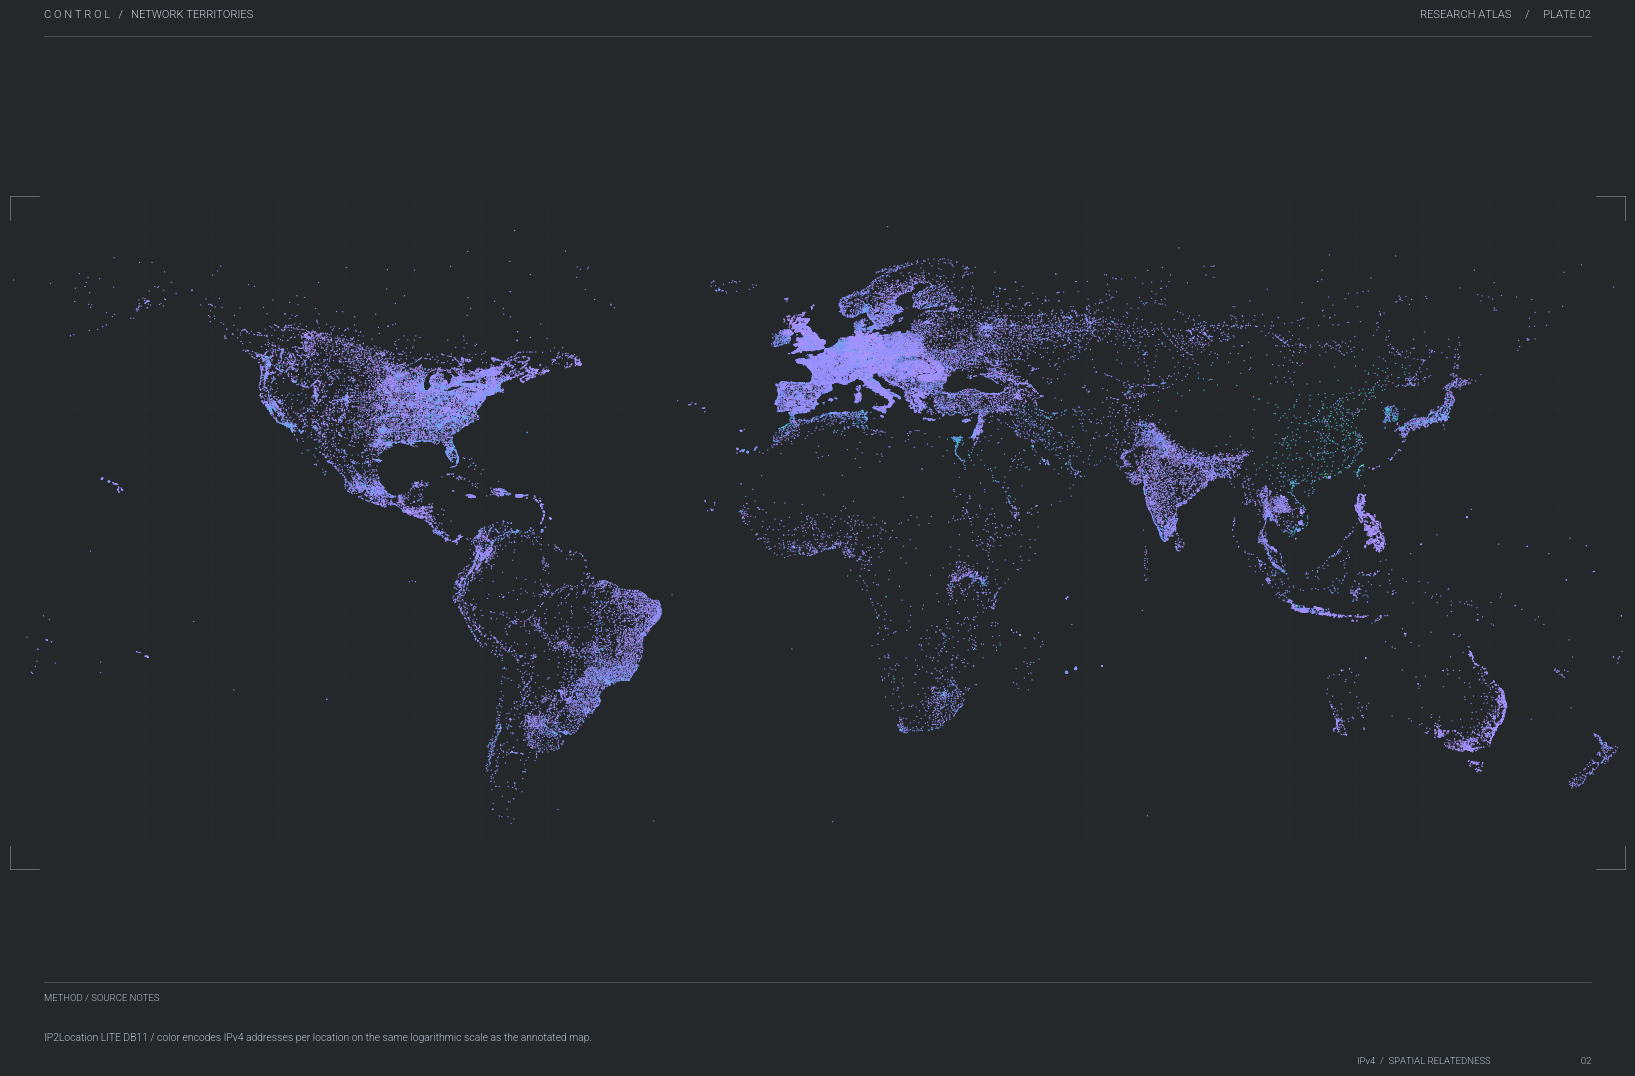

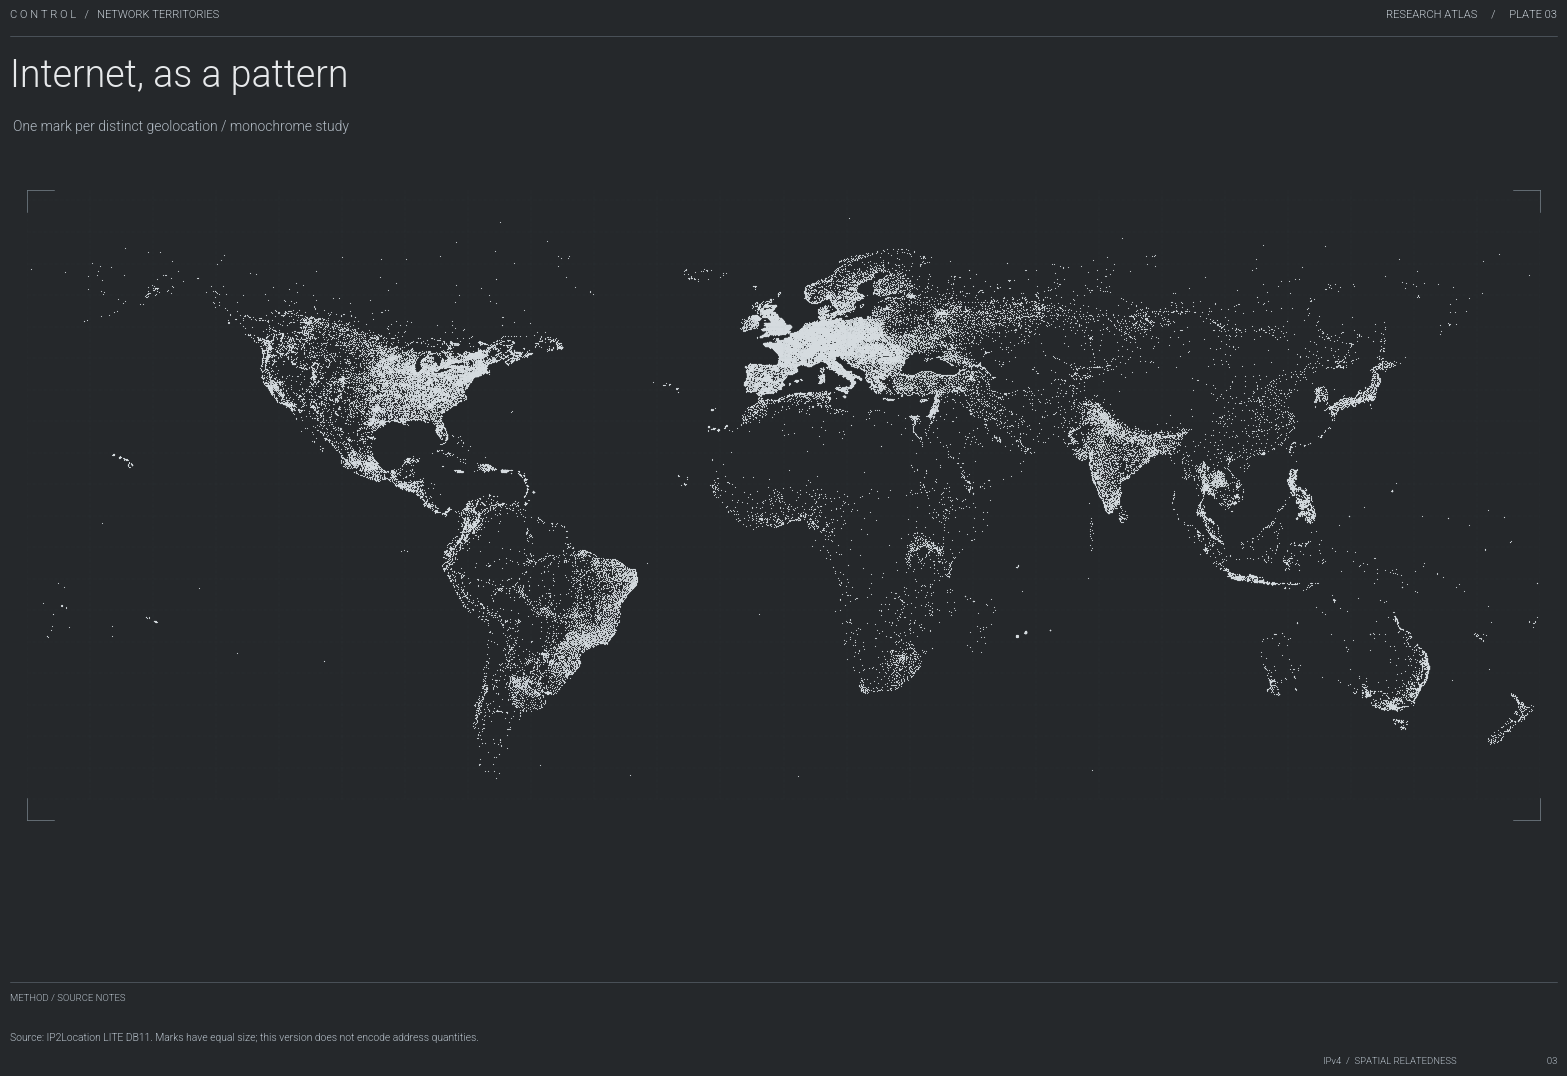

In [4]:
# Preserve the annotated, clean and monochrome versions of the global map.
location_norm = LogNorm(vmin=locations["ip_count"].min(), vmax=locations["ip_count"].max())
fig, ax = page("Internet, emerging", "IPv4 geolocation patterns / quantity at each database-assigned position")
draw_points(ax, locations, "ip_count", location_norm)
add_scale(fig, location_norm, "IPv4 addresses per location / logarithmic scale")
export_page(fig, "01_internet_locations.pdf",
            "Source: IP2Location LITE DB11. Points are estimated geolocations, not individual servers or devices.")

fig = plt.figure(figsize=PAGE_SIZE)
ax = fig.add_axes([0.025, 0.08, 0.95, 0.84])
draw_points(ax, locations, "ip_count", location_norm)
export_page(fig, "IpAddresses2026.pdf",
            "IP2Location LITE DB11 / color encodes IPv4 addresses per location on the same logarithmic scale as the annotated map.")

fig, ax = page("Internet, as a pattern", "One mark per distinct geolocation / monochrome study")
draw_points(ax, locations, color="#d6dce0", size=0.7)
export_page(fig, "IpAddresses2026-bw.pdf",
            "Source: IP2Location LITE DB11. Marks have equal size; this version does not encode address quantities.")

## Chapter 3 / Unequal address space
Aggregate geolocated IPv4 by country. Colored discrete plus signs represents the national total; geographic outlines provide a territorial reference.

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


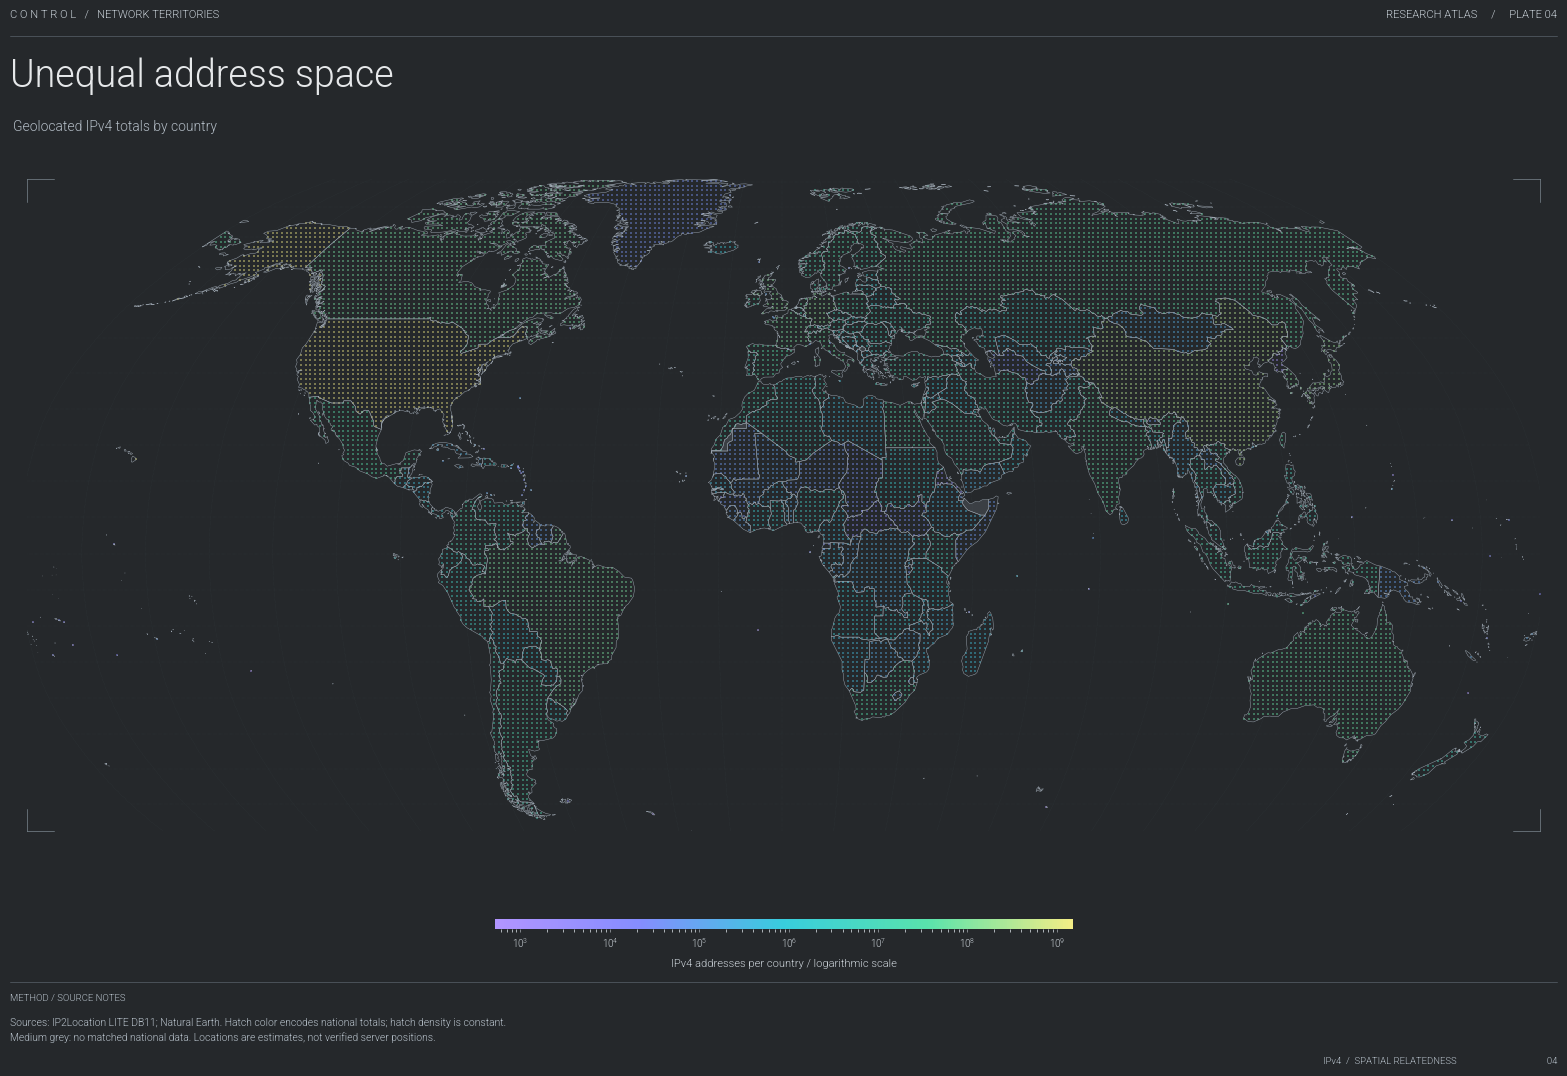

In [5]:
country_norm = LogNorm(vmin=country_counts["ipv4_count"].min(), vmax=country_counts["ipv4_count"].max())
fig, ax = page("Unequal address space", "Geolocated IPv4 totals by country")
draw_countries(ax, country_counts, "ipv4_count", country_norm)
add_scale(fig, country_norm, "IPv4 addresses per country / logarithmic scale")
export_page(fig, "ipv4_totals_by_country.pdf",
    "Sources: IP2Location LITE DB11; Natural Earth. Hatch color encodes national totals; hatch density is constant.\nMedium grey: no matched national data. Locations are estimates, not verified server positions.")

## Chapter 4 / Networks and organizations
Read CAIDA organization records and attach administrative country information to BGP origins. Keep multiple-origin prefixes ambiguous; a routing origin does not establish legal ownership.

In [6]:
# Read CAIDA's two sections: organizations and autonomous systems
as_org_path = DATA_DIR / "20261001.as-org2info.txt.gz"

organizations = []
autonomous_systems = []
section = None

with gzip.open(as_org_path, "rt", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if line.startswith("# format:"):
            fields = line.split(":", 1)[1].strip().split("|")
            section = fields[0]
            continue

        if not line or line.startswith("#"):
            continue

        values = line.split("|")

        if section == "org_id":
            organizations.append(dict(zip(fields, values)))
        elif section == "aut":
            autonomous_systems.append(dict(zip(fields, values)))

org_df = pd.DataFrame(organizations)
asn_df = pd.DataFrame(autonomous_systems)

# Keep the fields needed for the analysis
org_df = org_df[["org_id", "org_name", "country"]].rename(
    columns={
        "org_name": "organization",
        "country": "organization_country"
    }
)

asn_df = asn_df[["aut", "aut_name", "org_id"]].rename(
    columns={"aut": "asn", "aut_name": "asn_name"}
)
asn_df["asn"] = pd.to_numeric(asn_df["asn"], errors="raise")

# Link each ASN to its organization
asn_organizations = asn_df.merge(
    org_df,
    on="org_id",
    how="left",
    validate="many_to_one"
)

# Treat missing country codes as unknown
asn_organizations["organization_country"] = (
    asn_organizations["organization_country"]
    .replace({"": pd.NA, "-": pd.NA, "??": pd.NA})
)

output_path = OUTPUT_DIR / "asn_organizations.csv"
asn_organizations.to_csv(output_path, index=False)

print(f"ASN loaded: {len(asn_organizations):,}")
print(
    "ASN without an organization country:",
    asn_organizations["organization_country"].isna().sum()
)
print(f"Saved to: {output_path}")

asn_organizations.head(10)

ASN loaded: 122,668
ASN without an organization country: 0
Saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignement 03 Spatial Relatedness/output/asn_organizations.csv


,asn,asn_name,org_id,organization,organization_country
0,1,LVLT-1,LPL-141-ARIN,"Level 3 Parent, LLC",US
1,2,UDEL-DCN,UNIVER-19-Z-ARIN,University of Delaware,US
2,3,MIT-GATEWAYS,MIT-2-ARIN,Massachusetts Institute of Technology,US
3,4,ISI-AS,USC-32-Z-ARIN,University of Southern California,US
4,5,SYMBOLICS,WGL-117-ARIN,WFA Group LLC,US
5,6,BULL-HN,ATOS-Z-ARIN,"ATOS IT Solutions and Services, Inc.",US
6,7,DSTL,ORG-TDSA4-RIPE,The Defence Science and Technology Laboratory,GB
7,8,RICE-AS,RICEUN-ARIN,Rice University,US
8,9,CMU-ROUTER,CARNEG-Z-ARIN,Carnegie Mellon University,US
9,10,CSNET-EXT-AS,CCICC-ARIN,CSNET Coordination and Information Center (CSN...,US


In [7]:
prefix_path = DATA_DIR / "routeviews-rv2-20261001-1200.pfx2as.gz"

prefixes = pd.read_csv(
    prefix_path,
    sep="\t",
    header=None,
    names=["prefix", "prefix_length", "origin_asn"],
    dtype={
        "prefix": "string",
        "prefix_length": "int64",
        "origin_asn": "string"
    }
)

# Convert IPv4 prefixes to inclusive numeric intervals
prefixes["ip_start"] = prefixes["prefix"].map(
    lambda value: int(ipaddress.IPv4Address(value))
)
prefixes["ip_count"] = 2 ** (32 - prefixes["prefix_length"])
prefixes["ip_end"] = (
    prefixes["ip_start"] + prefixes["ip_count"] - 1
)

# Keep multiple-origin and AS-set records separate from single-ASN records
single_origin = prefixes["origin_asn"].str.fullmatch(r"\d+", na=False)

prefixes["origin_status"] = single_origin.map({
    True: "single",
    False: "multiple_or_set"
})

prefixes["asn"] = pd.to_numeric(
    prefixes["origin_asn"].where(single_origin),
    errors="raise"
).astype("Int64")

# Attach organization metadata only where a single ASN is available
prefixes = prefixes.merge(
    asn_organizations[
        ["asn", "asn_name", "organization", "organization_country"]
    ],
    on="asn",
    how="left",
    validate="many_to_one"
)

# Validate the numeric intervals
assert prefixes["prefix_length"].between(0, 32).all()
assert prefixes["ip_end"].le(2**32 - 1).all()

output_path = OUTPUT_DIR / "ipv4_prefixes_organizations.csv.gz"
prefixes.to_csv(output_path, index=False, compression="gzip")

print(f"Prefixes loaded: {len(prefixes):,}")
print(
    "Prefixes with multiple origins or AS sets:",
    f"{(~single_origin).sum():,}"
)
print(
    "Prefixes with an organization country:",
    f"{prefixes['organization_country'].notna().sum():,}"
)
print(f"Saved to: {output_path}")

prefixes.head(10)

Prefixes loaded: 1,125,729
Prefixes with multiple origins or AS sets: 4,449
Prefixes with an organization country: 1,120,155
Saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignement 03 Spatial Relatedness/output/ipv4_prefixes_organizations.csv.gz


,prefix,prefix_length,origin_asn,ip_start,ip_count,ip_end,origin_status,asn,asn_name,organization,organization_country
0,1.0.0.0,24,13335,16777216,256,16777471,single,13335,CLOUDFLARENET,"Cloudflare, Inc.",US
1,1.0.4.0,24,38803,16778240,256,16778495,single,38803,GTELECOM-AS-AP,Gtelecom Pty Ltd,AU
2,1.0.5.0,24,38803,16778496,256,16778751,single,38803,GTELECOM-AS-AP,Gtelecom Pty Ltd,AU
3,1.0.6.0,24,38803,16778752,256,16779007,single,38803,GTELECOM-AS-AP,Gtelecom Pty Ltd,AU
4,1.0.7.0,24,38803,16779008,256,16779263,single,38803,GTELECOM-AS-AP,Gtelecom Pty Ltd,AU
5,1.0.16.0,24,2519,16781312,256,16781567,single,2519,Vectant,ARTERIA Networks Corporation,JP
6,1.0.64.0,18,18144,16793600,16384,16809983,single,18144,MEGAEGG,"Energia Communications,Inc.",JP
7,1.0.128.0,17,23969,16809984,32768,16842751,single,23969,TOT-NET,Royal Thai Armed Force Headquarters,TH
8,1.0.128.0,18,23969,16809984,16384,16826367,single,23969,TOT-NET,Royal Thai Armed Force Headquarters,TH
9,1.0.128.0,19,23969,16809984,8192,16818175,single,23969,TOT-NET,Royal Thai Armed Force Headquarters,TH


## Chapter 5 / Count each address once
Use the most specific observed prefix where BGP prefixes overlap. This creates disjoint intervals for subsequent intersections.

In [8]:
# Load prefixes, preserving country codes such as "NA" (Namibia).

assert not prefixes.duplicated(["ip_start", "prefix_length"]).any()

prefixes = prefixes.sort_values(
    ["ip_start", "prefix_length"],
    ascending=[True, False]
).reset_index(drop=True)

# Use exclusive end addresses to simplify interval comparisons.
starts = prefixes["ip_start"].to_numpy(dtype=np.int64)
stops = prefixes["ip_end"].to_numpy(dtype=np.int64) + 1
lengths = prefixes["prefix_length"].to_numpy(dtype=np.int64)
boundaries = np.unique(np.concatenate([starts, stops]))

active = []
segments = []
cursor = 0

# Select the most specific prefix covering each interval.
for left, right in zip(boundaries[:-1], boundaries[1:]):
    while cursor < len(prefixes) and starts[cursor] <= left:
        heapq.heappush(
            active,
            (-int(lengths[cursor]), cursor, int(stops[cursor]))
        )
        cursor += 1

    while active and active[0][2] <= left:
        heapq.heappop(active)

    if not active:
        continue

    prefix_id = active[0][1]

    # Merge adjacent intervals assigned to the same prefix.
    if (
        segments
        and segments[-1][2] == prefix_id
        and segments[-1][1] == left
    ):
        segments[-1][1] = int(right)
    else:
        segments.append([int(left), int(right), prefix_id])

routed_intervals = pd.DataFrame(
    segments,
    columns=["ip_start", "ip_stop", "prefix_id"]
)

routed_intervals["ip_end"] = routed_intervals["ip_stop"] - 1
routed_intervals["ip_count"] = (
    routed_intervals["ip_stop"] - routed_intervals["ip_start"]
)

# Attach organization metadata to the selected intervals.
metadata = prefixes[
    [
        "prefix", "prefix_length", "origin_asn", "origin_status",
        "asn", "organization", "organization_country"
    ]
].rename_axis("prefix_id").reset_index()

routed_intervals = routed_intervals.merge(
    metadata,
    on="prefix_id",
    how="left",
    validate="many_to_one"
)

# Check that intervals do not overlap and contain valid address counts.
assert (
    routed_intervals["ip_start"].to_numpy()[1:]
    >= routed_intervals["ip_stop"].to_numpy()[:-1]
).all()
assert routed_intervals["ip_count"].gt(0).all()

output_path = OUTPUT_DIR / "ipv4_routed_intervals.csv.gz"
routed_intervals.to_csv(output_path, index=False, compression="gzip")

print(f"Non-overlapping intervals: {len(routed_intervals):,}")
print(f"Unique routed IPv4 addresses: {routed_intervals['ip_count'].sum():,}")
print(f"Saved to: {output_path}")

routed_intervals.head(10)

Non-overlapping intervals: 1,168,242
Unique routed IPv4 addresses: 3,127,700,848
Saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignement 03 Spatial Relatedness/output/ipv4_routed_intervals.csv.gz


,ip_start,ip_stop,prefix_id,ip_end,ip_count,prefix,prefix_length,origin_asn,origin_status,asn,organization,organization_country
0,16777216,16777472,0,16777471,256,1.0.0.0,24,13335,single,13335,"Cloudflare, Inc.",US
1,16778240,16778496,1,16778495,256,1.0.4.0,24,38803,single,38803,Gtelecom Pty Ltd,AU
2,16778496,16778752,2,16778751,256,1.0.5.0,24,38803,single,38803,Gtelecom Pty Ltd,AU
3,16778752,16779008,3,16779007,256,1.0.6.0,24,38803,single,38803,Gtelecom Pty Ltd,AU
4,16779008,16779264,4,16779263,256,1.0.7.0,24,38803,single,38803,Gtelecom Pty Ltd,AU
5,16781312,16781568,5,16781567,256,1.0.16.0,24,2519,single,2519,ARTERIA Networks Corporation,JP
6,16793600,16809984,6,16809983,16384,1.0.64.0,18,18144,single,18144,"Energia Communications,Inc.",JP
7,16809984,16810240,7,16810239,256,1.0.128.0,24,23969,single,23969,Royal Thai Armed Force Headquarters,TH
8,16810240,16810496,11,16810495,256,1.0.129.0,24,23969,single,23969,Royal Thai Armed Force Headquarters,TH
9,16810496,16811008,12,16811007,512,1.0.130.0,23,23969,single,23969,Royal Thai Armed Force Headquarters,TH


## Chapter 6 / Territory and administrative distance
Intersect geolocation and routing intervals. Compare the geolocated country with the country recorded for the origin-AS organization, preserving unknown and ambiguous assignments.

In [9]:
routed = pd.read_csv(
    OUTPUT_DIR / "ipv4_routed_intervals.csv.gz",
    keep_default_na=False,
    na_values=[""]
).sort_values("ip_start").reset_index(drop=True)

geo_country = geo["country_code"].replace({"-": "", "": ""})

g_start = geo["ip_start"].to_numpy()
g_end = geo["ip_end"].to_numpy()
g_country = geo_country.to_numpy()

r_start = routed["ip_start"].to_numpy(dtype=np.int64)
r_end = routed["ip_end"].to_numpy(dtype=np.int64)
r_country = routed["organization_country"].fillna("").to_numpy()
r_status = routed["origin_status"].to_numpy()

totals = defaultdict(int)
i = j = 0

# Intersect the two sorted interval tables without double counting.
while i < len(geo) and j < len(routed):
    left = max(g_start[i], r_start[j])
    right = min(g_end[i], r_end[j])

    if left <= right:
        country = g_country[i]
        org_country = r_country[j]

        if not country:
            relationship = "unknown_geolocation"
        elif r_status[j] != "single":
            relationship = "ambiguous_origin"
        elif not org_country:
            relationship = "unknown_organization"
        elif country == org_country:
            relationship = "domestic"
        else:
            relationship = "foreign"

        totals[(country, org_country, relationship)] += int(
            right - left + 1
        )

    if g_end[i] < r_end[j]:
        i += 1
    elif r_end[j] < g_end[i]:
        j += 1
    else:
        i += 1
        j += 1

relationships = pd.DataFrame(
    [
        (*key, count)
        for key, count in totals.items()
    ],
    columns=[
        "geo_country", "organization_country",
        "relationship", "ip_count"
    ]
)

# Summarize routed addresses with known geolocation by country.
categories = [
    "domestic", "foreign",
    "unknown_organization", "ambiguous_origin"
]

country_summary = (
    relationships.loc[relationships["geo_country"].ne("")]
    .pivot_table(
        index="geo_country",
        columns="relationship",
        values="ip_count",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(columns=categories, fill_value=0)
    .reset_index()
)

country_summary.columns.name = None
country_summary["total_ips"] = country_summary[categories].sum(axis=1)

for category in categories:
    country_summary[f"{category}_pct"] = (
        100 * country_summary[category] / country_summary["total_ips"]
    )

relationships.to_csv(
    OUTPUT_DIR / "ipv4_country_relationships.csv", index=False
)
country_summary.to_csv(
    OUTPUT_DIR / "ipv4_country_summary.csv", index=False
)

matched = int(relationships["ip_count"].sum())
total_routed = int(routed["ip_count"].sum())

assert matched <= total_routed

print(f"Routed IPv4 matched to IP2Location: {matched:,}")
print(f"Routed IPv4 outside IP2Location coverage: {total_routed - matched:,}")
print(f"Countries summarized: {len(country_summary):,}")

country_summary.sort_values(
    "foreign_pct", ascending=False
).head(15)

Routed IPv4 matched to IP2Location: 3,127,700,848
Routed IPv4 outside IP2Location coverage: 0
Countries summarized: 245


,geo_country,domestic,foreign,unknown_organization,ambiguous_origin,total_ips,domestic_pct,foreign_pct,unknown_organization_pct,ambiguous_origin_pct
177,PN,0,512,0,0,512,0.000000,100.000000,0.000000,0.0
195,SH,0,512,0,0,512,0.000000,100.000000,0.000000,0.0
33,BV,0,1792,0,0,1792,0.000000,100.000000,0.000000,0.0
227,UM,0,768,0,0,768,0.000000,100.000000,0.000000,0.0
86,GS,0,512,0,0,512,0.000000,100.000000,0.000000,0.0
92,HM,0,512,0,0,512,0.000000,100.000000,0.000000,0.0
197,SJ,0,512,0,0,512,0.000000,100.000000,0.000000,0.0
241,YT,1024,29952,0,0,30976,3.305785,96.694215,0.000000,0.0
76,GF,3840,98048,0,0,101888,3.768844,96.231156,0.000000,0.0
4,AI,512,10752,0,0,11264,4.545455,95.454545,0.000000,0.0


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


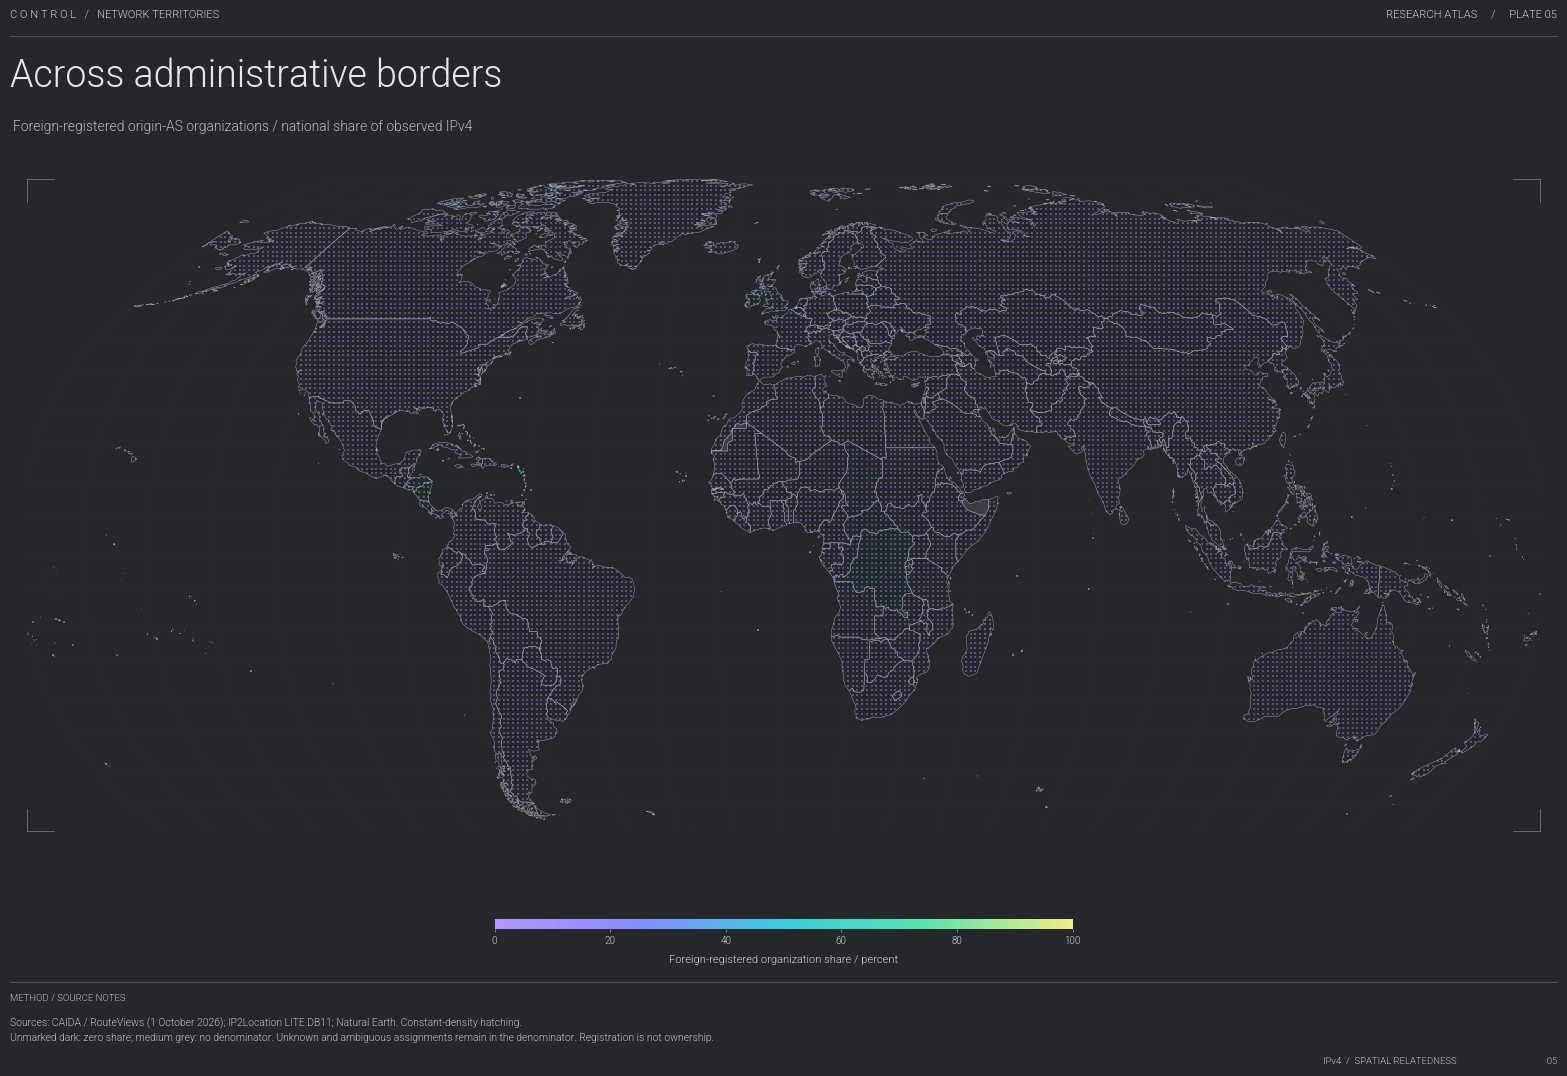

In [10]:
foreign_countries = country_summary.rename(columns={"geo_country": "country_code"})
percent_norm = Normalize(0, 100)
fig, ax = page("Across administrative borders", "Foreign-registered origin-AS organizations / national share of observed IPv4")
draw_countries(ax, foreign_countries, "foreign_pct", percent_norm)
add_scale(fig, percent_norm, "Foreign-registered organization share / percent")
export_page(fig, "ipv4_foreign_organizations.pdf",
    "Sources: CAIDA / RouteViews (1 October 2026); IP2Location LITE DB11; Natural Earth. Constant-density hatching.\nUnmarked dark: zero share; medium grey: no denominator. Unknown and ambiguous assignments remain in the denominator. Registration is not ownership.")

## Chapter 7 / Published corporate footprints
Normalize Google, Google Cloud, AWS and Azure lists. Collapse overlaps within each list, but keep the four lists separate: their coverage differs and Google Cloud overlaps Google.

In [11]:
rows = []

def add_prefix(dataset, company, prefix, region="", service=""):
    network = ipaddress.ip_network(prefix)

    if network.version == 4:
        rows.append({
            "dataset": dataset,
            "company": company,
            "prefix": str(network),
            "ip_start": int(network.network_address),
            "ip_end": int(network.broadcast_address),
            "region": region,
            "service": service
        })

# Read Google and Google Cloud as separate, overlapping datasets.
for filename, dataset in [
    ("google_goog.json", "Google"),
    ("google_cloud.json", "Google Cloud")
]:
    with open(DATA_DIR / filename) as file:
        data = json.load(file)

    for item in data["prefixes"]:
        if "ipv4Prefix" in item:
            add_prefix(
                dataset, "Google", item["ipv4Prefix"],
                item.get("scope", ""),
                item.get("service", "")
            )

# Read AWS prefixes and their service regions.
with open(DATA_DIR / "aws_ip_ranges.json") as file:
    data = json.load(file)

for item in data["prefixes"]:
    add_prefix(
        "AWS", "Amazon", item["ip_prefix"],
        item.get("region", ""),
        item.get("service", "")
    )

# Read Azure service tags; the same prefix may occur in several tags.
with open(DATA_DIR / "ServiceTags_Public_20261019.json") as file:
    data = json.load(file)

for item in data["values"]:
    properties = item["properties"]

    for prefix in properties["addressPrefixes"]:
        add_prefix(
            "Azure Public", "Microsoft", prefix,
            properties.get("region", ""),
            item["name"]
        )

bigtech_prefixes = pd.DataFrame(rows).drop_duplicates()

# Collapse overlapping prefixes before counting unique IPv4 addresses.
unique_rows = []

for dataset, group in bigtech_prefixes.groupby("dataset"):
    networks = [
        ipaddress.ip_network(prefix)
        for prefix in group["prefix"].unique()
    ]

    for network in ipaddress.collapse_addresses(networks):
        unique_rows.append({
            "dataset": dataset,
            "company": group["company"].iloc[0],
            "prefix": str(network),
            "ip_start": int(network.network_address),
            "ip_end": int(network.broadcast_address),
            "ipv4_count": network.num_addresses
        })

bigtech_intervals = pd.DataFrame(unique_rows)

totals = (
    bigtech_intervals.groupby("dataset", as_index=False)
    .agg(
        unique_ipv4=("ipv4_count", "sum"),
        intervals=("prefix", "size")
    )
    .sort_values("unique_ipv4", ascending=False)
)

bigtech_prefixes.to_csv(
    OUTPUT_DIR / "bigtech_ipv4_prefixes.csv", index=False
)
bigtech_intervals.to_csv(
    OUTPUT_DIR / "bigtech_ipv4_unique_intervals.csv", index=False
)
totals.to_csv(
    OUTPUT_DIR / "bigtech_ipv4_totals.csv", index=False
)

print("Unique IPv4 addresses within each published dataset:")
print(totals.to_string(index=False))

Unique IPv4 addresses within each published dataset:
     dataset  unique_ipv4  intervals
         AWS    101987193       1745
Azure Public     54931552       1382
      Google     24211456        130
Google Cloud     19369344        461


## Chapter 8 / Locate published ranges
Intersect each list with geolocation intervals, retaining country and coordinates. Aggregate coincident locations for plotting and retain coverage statistics. Cloud region labels are not used as physical coordinates.

In [12]:
# Reuse one interval-intersection function for published lists and BGP organizations.
def locate_intervals(intervals, group_field):
    starts = geo["ip_start"].to_numpy()
    ends = geo["ip_end"].to_numpy()
    codes = geo["country_code"].to_numpy()
    latitudes = geo["latitude"].to_numpy()
    longitudes = geo["longitude"].to_numpy()
    mapped, coverage = [], []
    for label, group in intervals.groupby(group_field):
        counts = defaultdict(int)
        matched = 0
        for interval in group.itertuples(index=False):
            start, end = int(interval.ip_start), int(interval.ip_end)
            i = int(np.searchsorted(ends, start, side="left"))
            while i < len(geo) and starts[i] <= end:
                overlap = min(end, int(ends[i])) - max(start, int(starts[i])) + 1
                if overlap > 0:
                    country = codes[i] if codes[i] not in ["", "-"] else "UNKNOWN"
                    key = (country, latitudes[i], longitudes[i])
                    counts[key] += overlap
                    matched += overlap
                i += 1
        total = int((group["ip_end"] - group["ip_start"] + 1).sum())
        assert matched <= total
        mapped.extend((label, *key, count) for key, count in counts.items())
        coverage.append({group_field: label, "total_ipv4": total,
                         "matched_to_ip2location": matched, "outside_coverage": total - matched})
    return (pd.DataFrame(mapped, columns=[group_field, "country_code", "latitude", "longitude", "ip_count"]),
            pd.DataFrame(coverage))


def drawable(points):
    return points.loc[points["country_code"].ne("UNKNOWN") &
                      points["latitude"].between(-90, 90) &
                      points["longitude"].between(-180, 180)]

published_locations, published_coverage = locate_intervals(bigtech_intervals, "dataset")
published_locations.to_csv(OUTPUT_DIR / "bigtech_published_locations.csv.gz", index=False, compression="gzip")
published_coverage.to_csv(OUTPUT_DIR / "bigtech_geolocation_coverage.csv", index=False)
bigtech_countries = published_locations.groupby(["dataset", "country_code"], as_index=False)["ip_count"].sum()
bigtech_countries = bigtech_countries.rename(columns={"ip_count": "ipv4_count"})
bigtech_countries.to_csv(OUTPUT_DIR / "bigtech_ipv4_by_country.csv", index=False)
published_points = {label: drawable(published_locations.loc[published_locations["dataset"].eq(label)]) for label in SERVICES}
published_norm = LogNorm(vmin=min(p["ip_count"].min() for p in published_points.values()),
                        vmax=max(p["ip_count"].max() for p in published_points.values()))
display(published_coverage)

,dataset,total_ipv4,matched_to_ip2location,outside_coverage
0,AWS,101987193,101987193,0
1,Azure Public,54931552,54931552,0
2,Google,24211456,24211456,0
3,Google Cloud,19369344,19369344,0


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


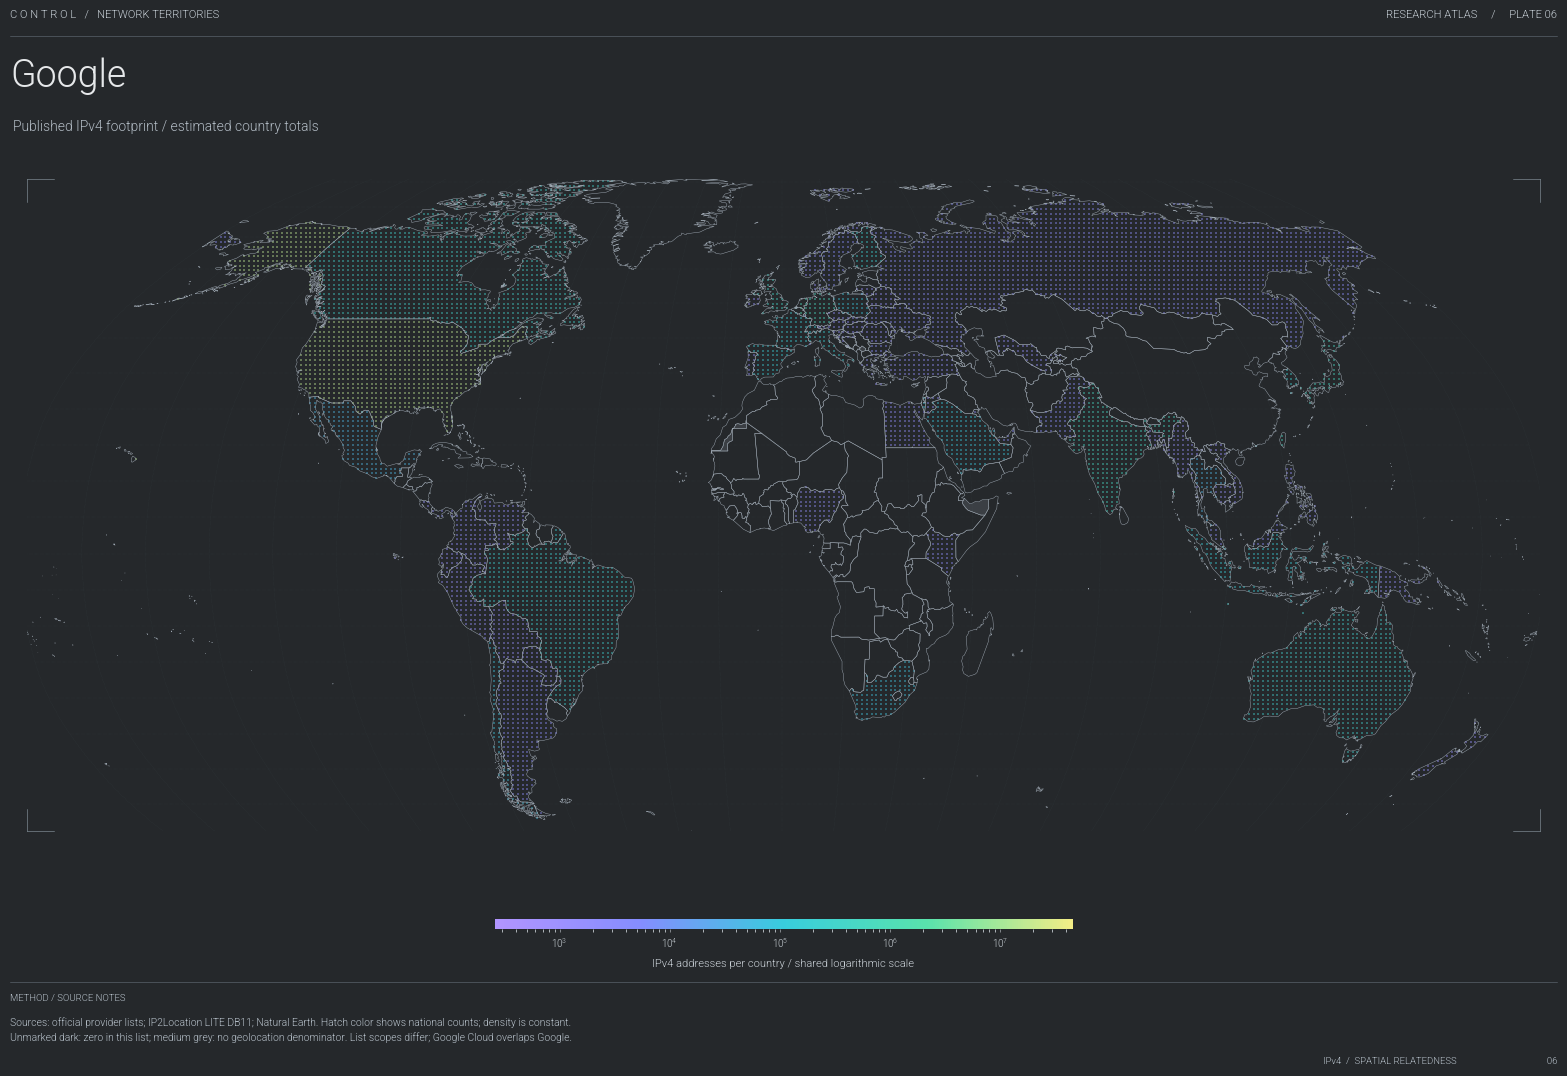

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


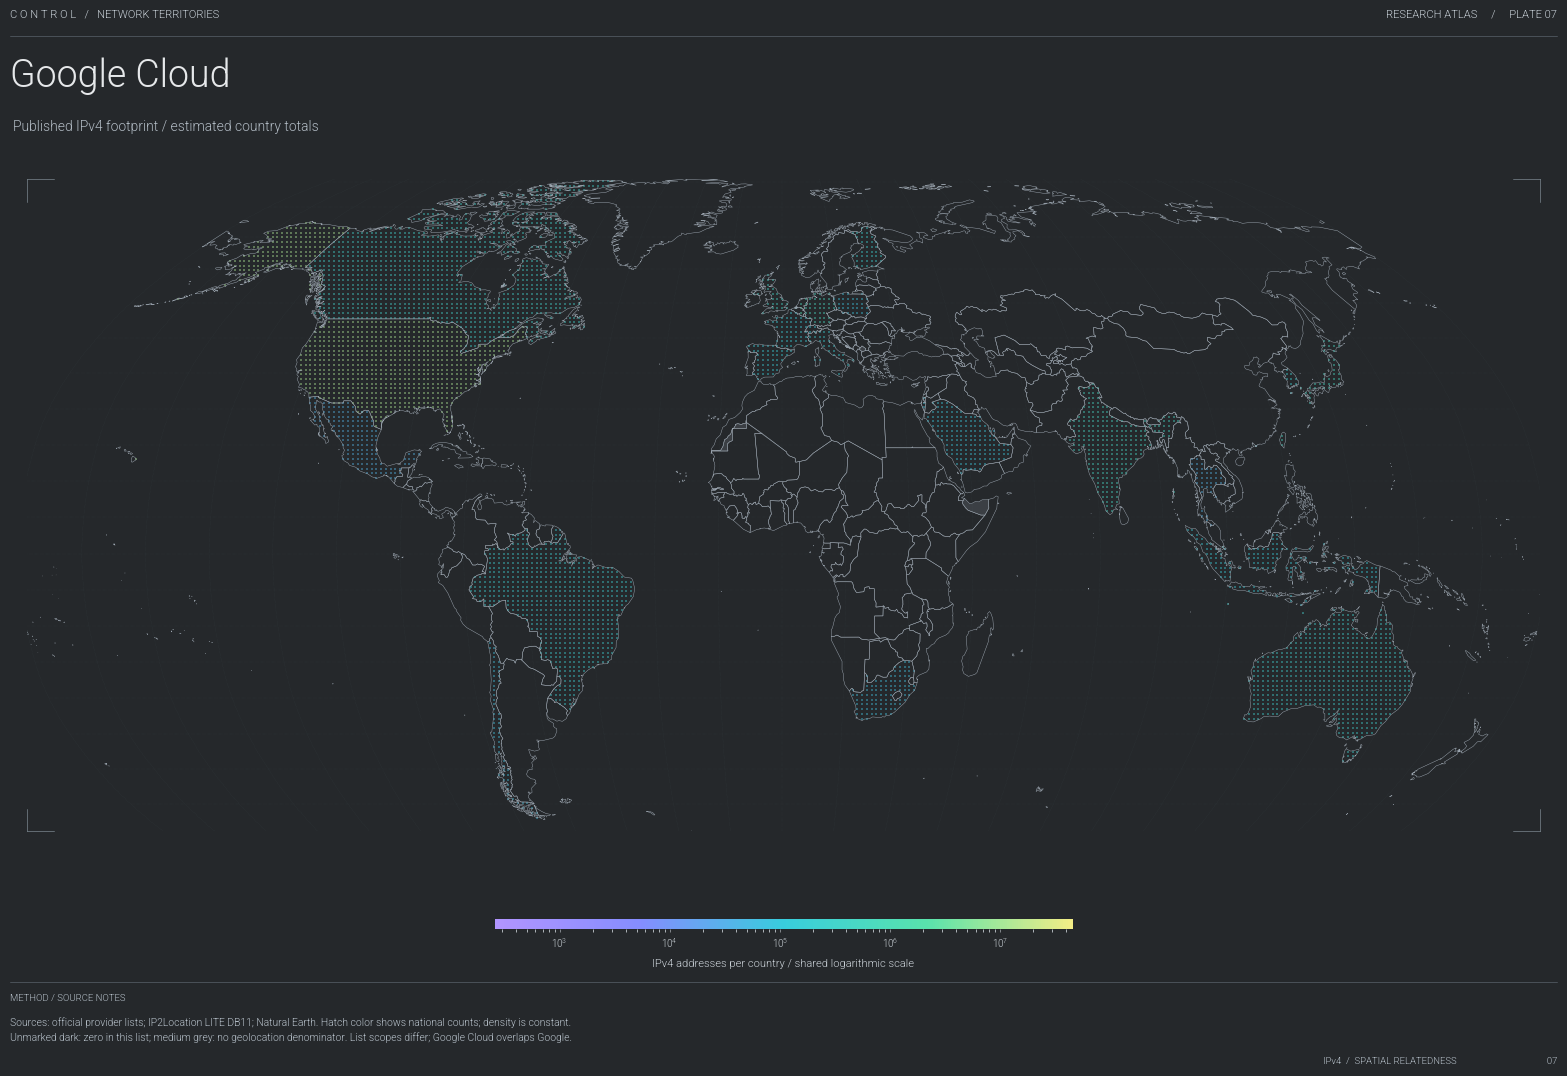

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


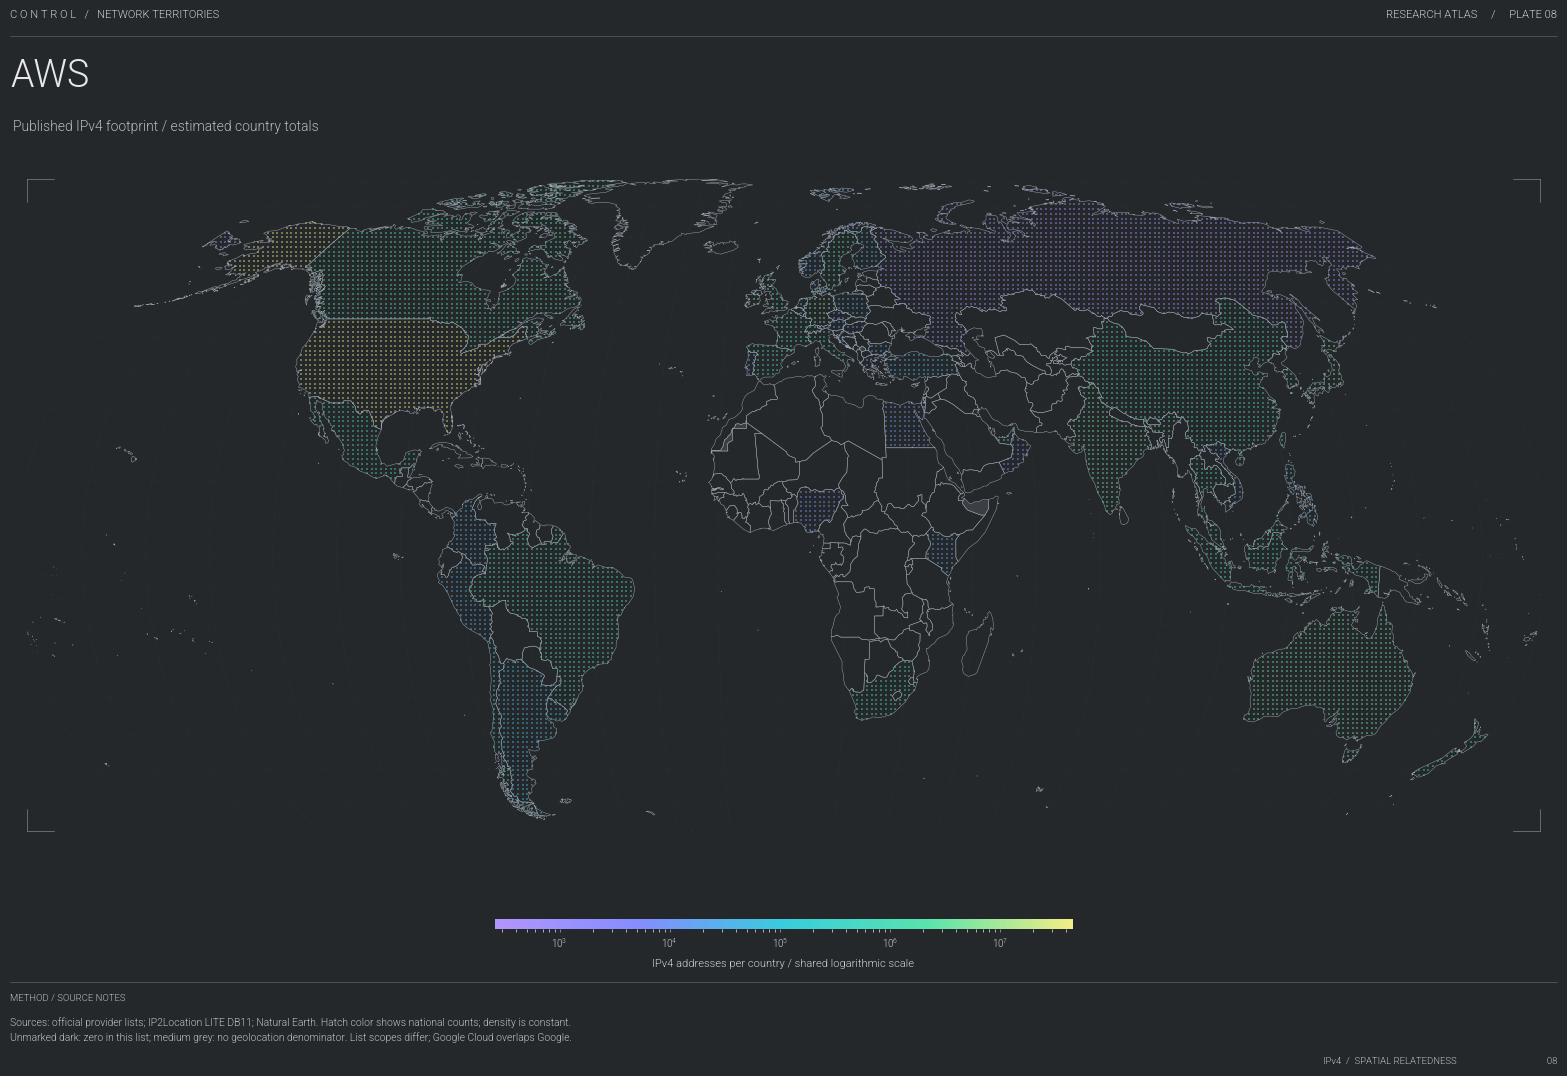

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


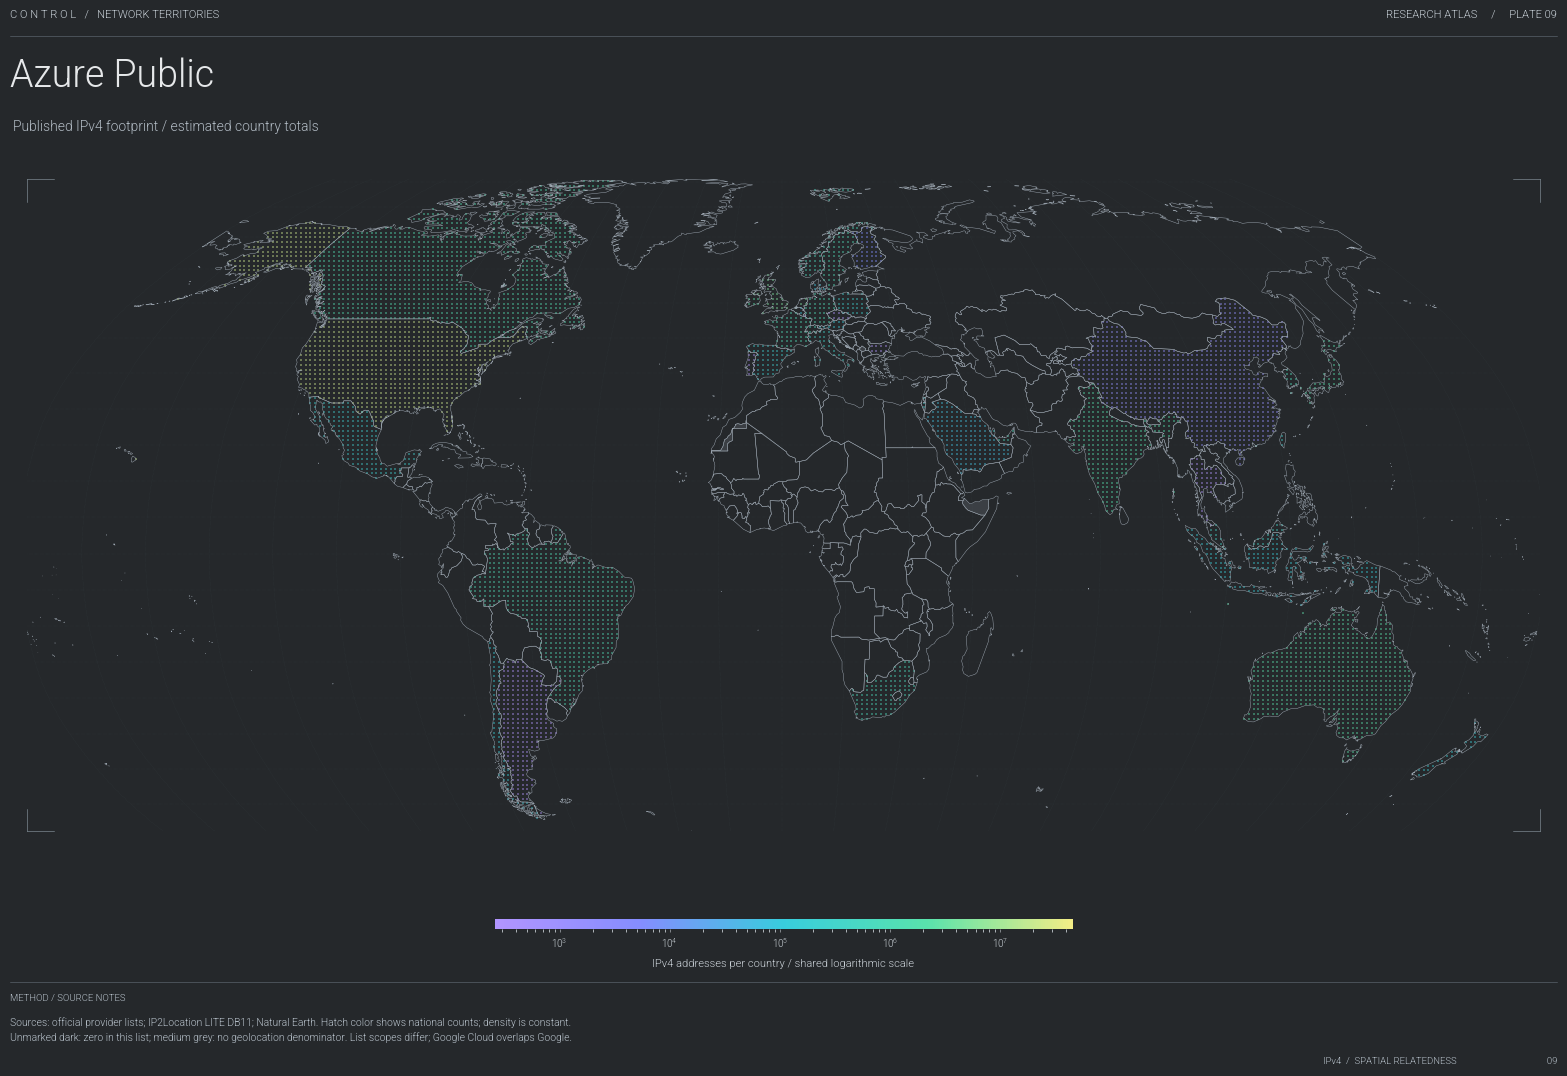

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']
Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


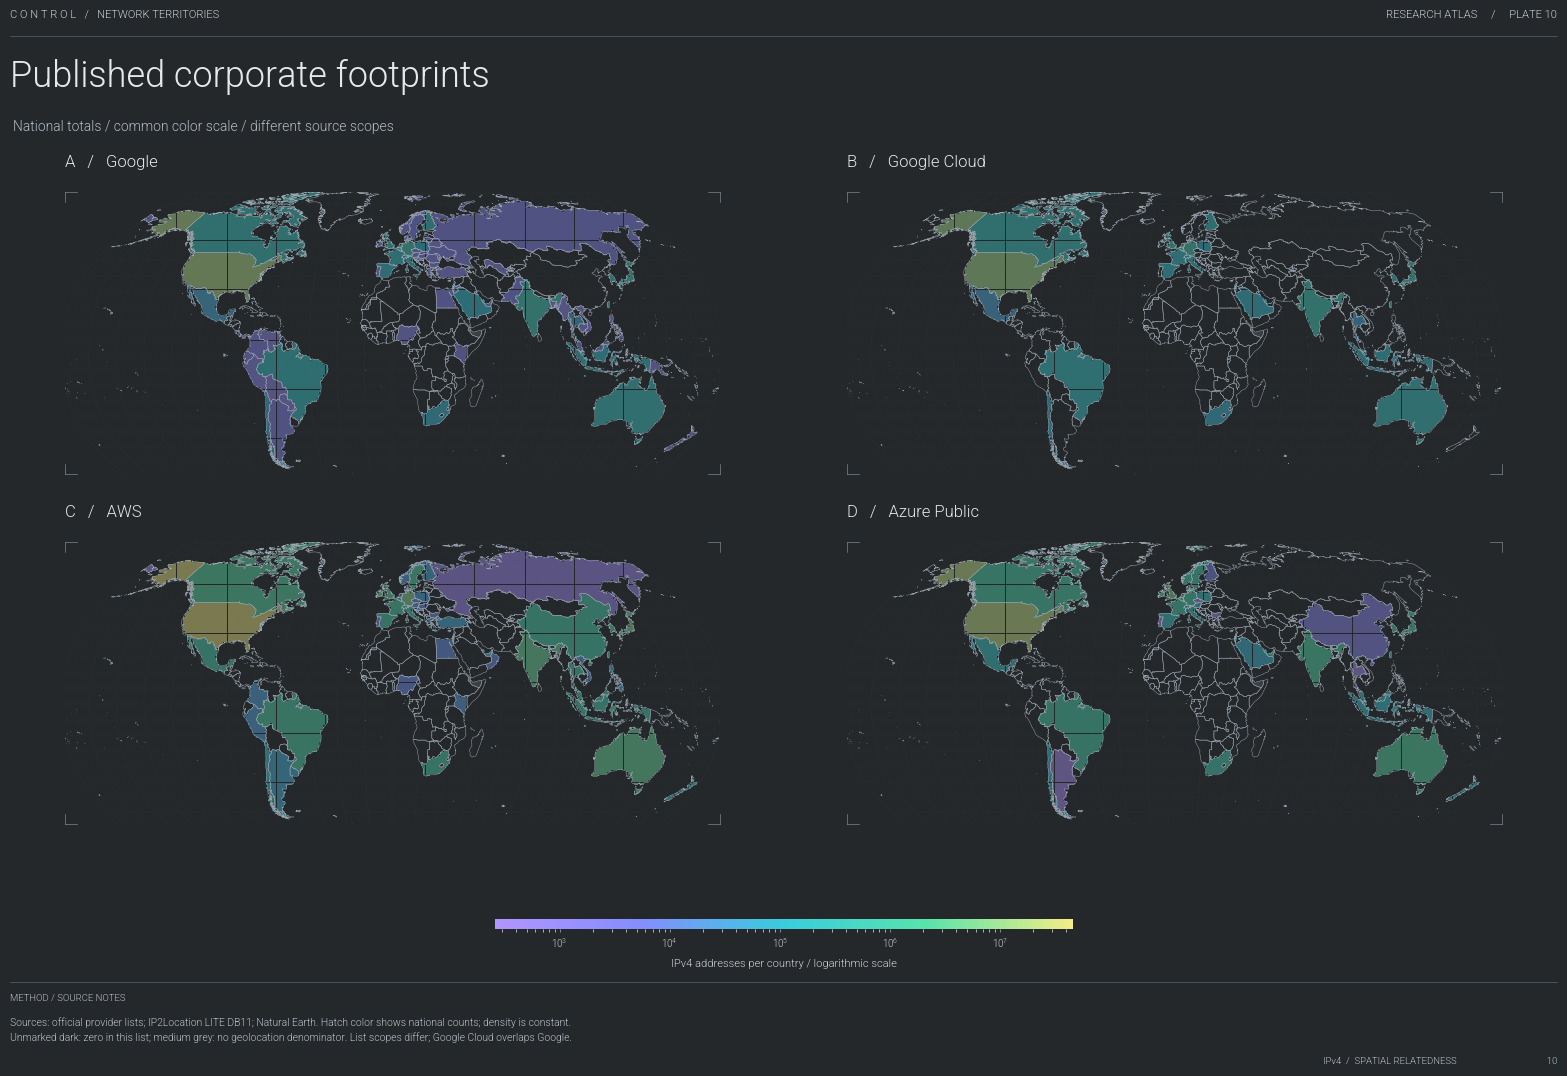

In [13]:
# Aggregate geolocations to countries before drawing patterned polygons.
published_tables = {}
for label in SERVICES:
    subset = bigtech_countries.loc[bigtech_countries["dataset"].eq(label), ["country_code", "ipv4_count"]]
    table = country_counts[["country_code"]].merge(subset, on="country_code", how="left", validate="one_to_one")
    table["ipv4_count"] = table["ipv4_count"].fillna(0)
    published_tables[label] = table
positive_counts = bigtech_countries.loc[bigtech_countries["country_code"].ne("UNKNOWN"), "ipv4_count"]
published_country_norm = LogNorm(positive_counts.min(), positive_counts.max())
published_note = ("Sources: official provider lists; IP2Location LITE DB11; Natural Earth. Hatch color shows national counts; density is constant.\n"
                  "Unmarked dark: zero in this list; medium grey: no geolocation denominator. List scopes differ; Google Cloud overlaps Google.")
for label in SERVICES:
    fig, ax = page(label, "Published IPv4 footprint / estimated country totals")
    draw_countries(ax, published_tables[label], "ipv4_count", published_country_norm)
    add_scale(fig, published_country_norm, "IPv4 addresses per country / shared logarithmic scale")
    export_page(fig, "published_" + label.lower().replace(" ", "_") + ".pdf", published_note)
country_panel(published_tables, SERVICES, "ipv4_count", published_country_norm,
              "Published corporate footprints", "National totals / common color scale / different source scopes",
              "bigtech_ipv4_country_maps.pdf", published_note,
              "IPv4 addresses per country / logarithmic scale")

## Chapter 9 / Compare like with like
Select the primary CAIDA organization associated with one reference ASN per company. Include all ASN records sharing that organization ID. This conservative scope is reproducible but may omit subsidiaries.

In [14]:
organizations = pd.read_csv(
    OUTPUT_DIR / "asn_organizations.csv",
    dtype={"asn": "Int64"},
    keep_default_na=False
)

routed = pd.read_csv(
    OUTPUT_DIR / "ipv4_routed_intervals.csv.gz",
    dtype={"asn": "Int64"},
    keep_default_na=False,
    na_values=[""]
)

# Identify each company's primary organization through a reference ASN.
reference_asns = {
    "Amazon": 16509,
    "Meta": 32934,
    "Google": 15169,
    "Microsoft": 8075
}

selected = []

for company, reference_asn in reference_asns.items():
    reference = organizations.loc[
        organizations["asn"].eq(reference_asn)
    ]

    if len(reference) != 1:
        raise ValueError(f"Reference ASN not uniquely identified: {company}")

    org_id = reference["org_id"].iloc[0]

    matches = organizations.loc[
        organizations["org_id"].eq(org_id)
    ].copy()

    matches["company"] = company
    selected.append(matches)

company_asns = pd.concat(selected, ignore_index=True)

# Each selected ASN must belong to only one comparison group.
assert not company_asns["asn"].duplicated().any()

# Keep single-origin intervals associated with the selected organizations.
company_intervals = routed.loc[
    routed["origin_status"].eq("single")
].merge(
    company_asns[["asn", "company"]],
    on="asn",
    how="inner",
    validate="many_to_one"
)

company_asns.to_csv(
    OUTPUT_DIR / "bigtech_selected_asns.csv",
    index=False
)

company_intervals.to_csv(
    OUTPUT_DIR / "bigtech_bgp_intervals.csv.gz",
    index=False,
    compression="gzip"
)

totals = (
    company_intervals.groupby("company", as_index=False)
    .agg(
        observed_ipv4=("ip_count", "sum"),
        announcing_asns=("asn", "nunique")
    )
    .sort_values("observed_ipv4", ascending=False)
)

totals.to_csv(
    OUTPUT_DIR / "bigtech_bgp_totals.csv",
    index=False
)

display(
    company_asns[
        ["company", "asn", "organization", "organization_country"]
    ].sort_values(["company", "asn"])
)

display(totals)

,company,asn,organization,organization_country
0,Amazon,7224,"Amazon.com, Inc.",US
1,Amazon,10291,"Amazon.com, Inc.",US
2,Amazon,16509,"Amazon.com, Inc.",US
3,Amazon,19047,"Amazon.com, Inc.",US
4,Amazon,63088,"Amazon.com, Inc.",US
...,...,...,...,...
75,Microsoft,400579,Microsoft Corporation,US
76,Microsoft,400580,Microsoft Corporation,US
77,Microsoft,400581,Microsoft Corporation,US
78,Microsoft,400582,Microsoft Corporation,US


,company,observed_ipv4,announcing_asns
0,Amazon,157590016,2
3,Microsoft,82653184,11
1,Google,850208,2
2,Meta,473344,2


## Chapter 10 / Corporate networks in geographic space
Locate the selected BGP intervals, count their addresses by country, and calculate their share of all BGP-observed, geolocated IPv4 in each country. Unlocated addresses remain in the coverage audit.

In [15]:
company_locations, company_coverage = locate_intervals(company_intervals, "company")
company_locations.to_csv(OUTPUT_DIR / "bigtech_bgp_locations.csv.gz", index=False, compression="gzip")
company_coverage.to_csv(OUTPUT_DIR / "bigtech_bgp_geolocation_coverage.csv", index=False)
company_countries = company_locations.groupby(["company", "country_code"], as_index=False)["ip_count"].sum()
company_countries = company_countries.rename(columns={"ip_count": "company_ipv4"})
country_totals = country_summary[["geo_country", "total_ips"]].rename(
    columns={"geo_country": "country_code", "total_ips": "country_observed_ipv4"})
company_countries = company_countries.merge(country_totals, on="country_code", how="left", validate="many_to_one")
known = company_countries["country_code"].ne("UNKNOWN")
assert company_countries.loc[known, "country_observed_ipv4"].notna().all()
assert (company_countries.loc[known, "company_ipv4"] <= company_countries.loc[known, "country_observed_ipv4"]).all()
company_countries["share_of_country_pct"] = 100 * company_countries["company_ipv4"] / company_countries["country_observed_ipv4"]
company_countries.to_csv(OUTPUT_DIR / "bigtech_bgp_by_country.csv", index=False)
company_points = {label: drawable(company_locations.loc[company_locations["company"].eq(label)]) for label in COMPANIES}
company_norm = LogNorm(vmin=min(p["ip_count"].min() for p in company_points.values()),
                      vmax=max(p["ip_count"].max() for p in company_points.values()))
display(company_coverage)

,company,total_ipv4,matched_to_ip2location,outside_coverage
0,Amazon,157590016,157590016,0
1,Google,850208,850208,0
2,Meta,473344,473344,0
3,Microsoft,82653184,82653184,0


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


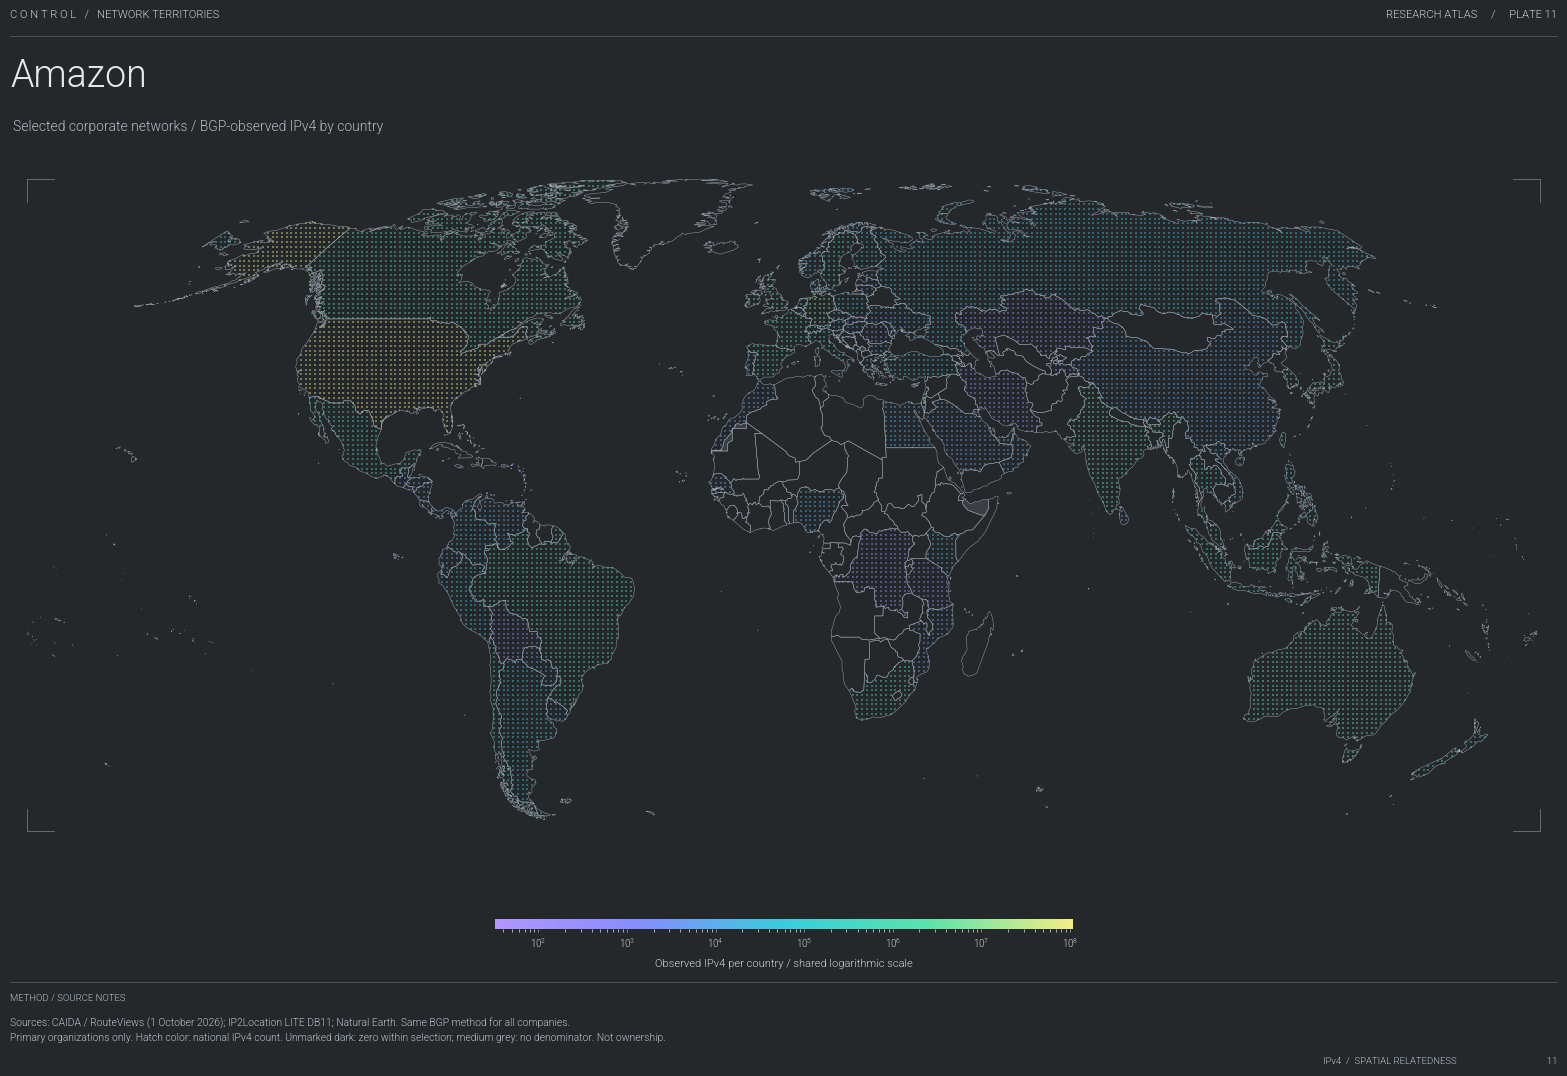

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


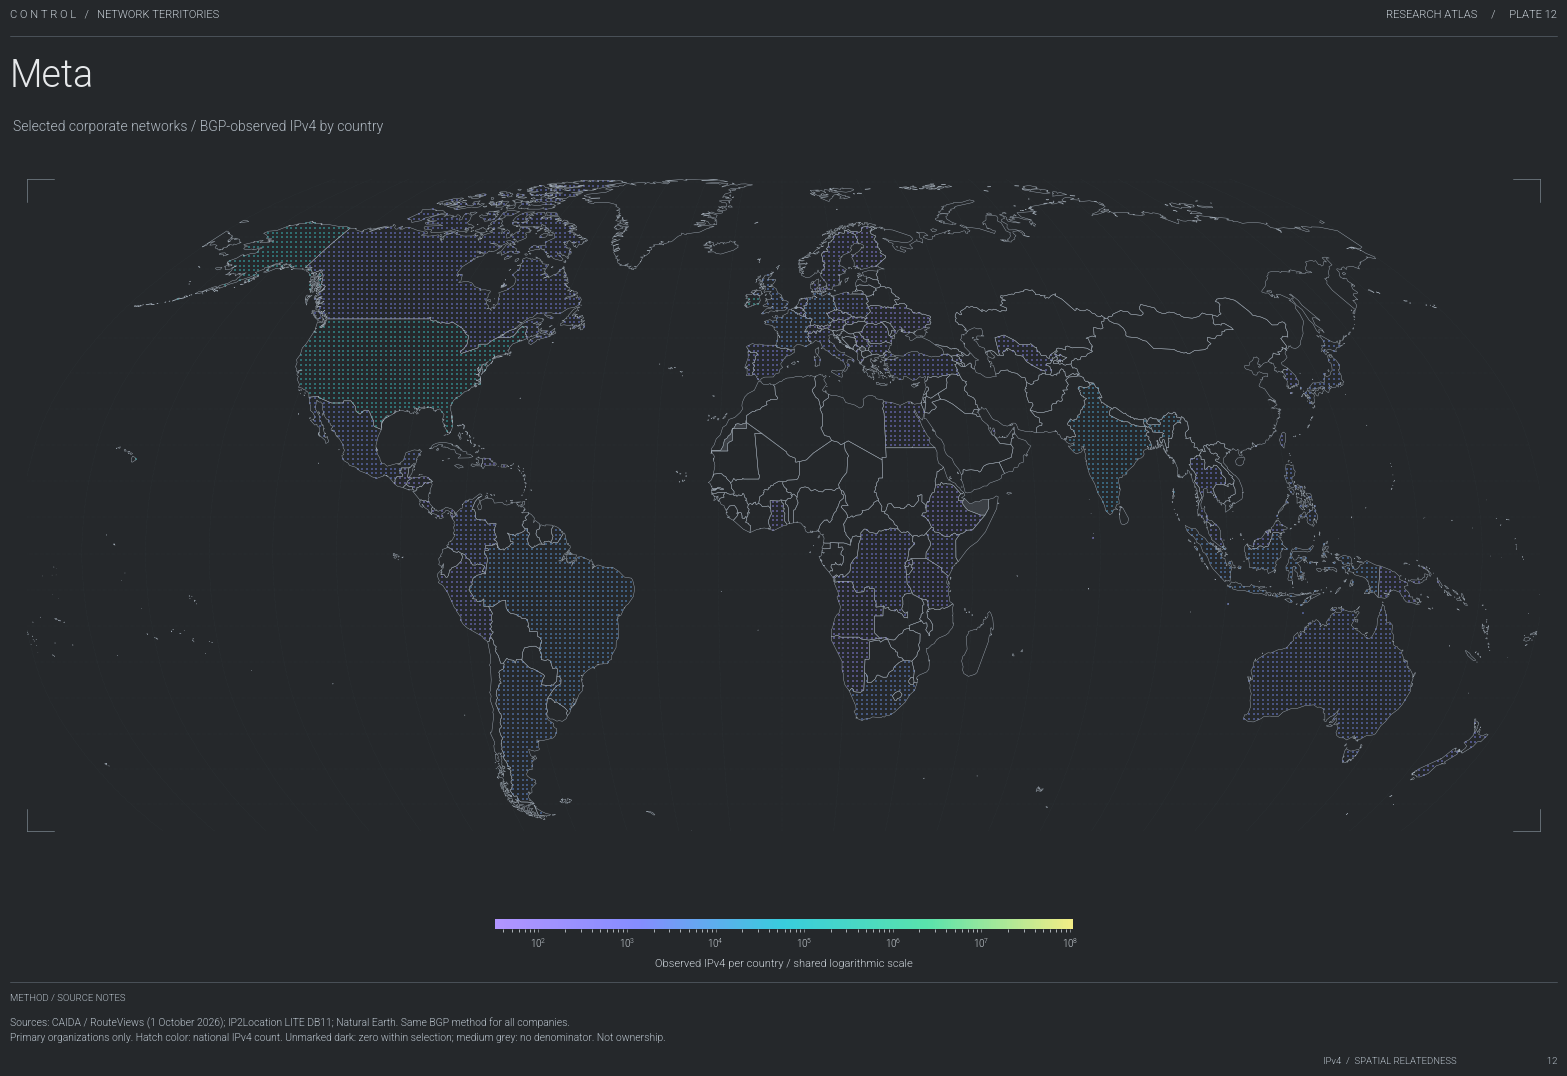

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


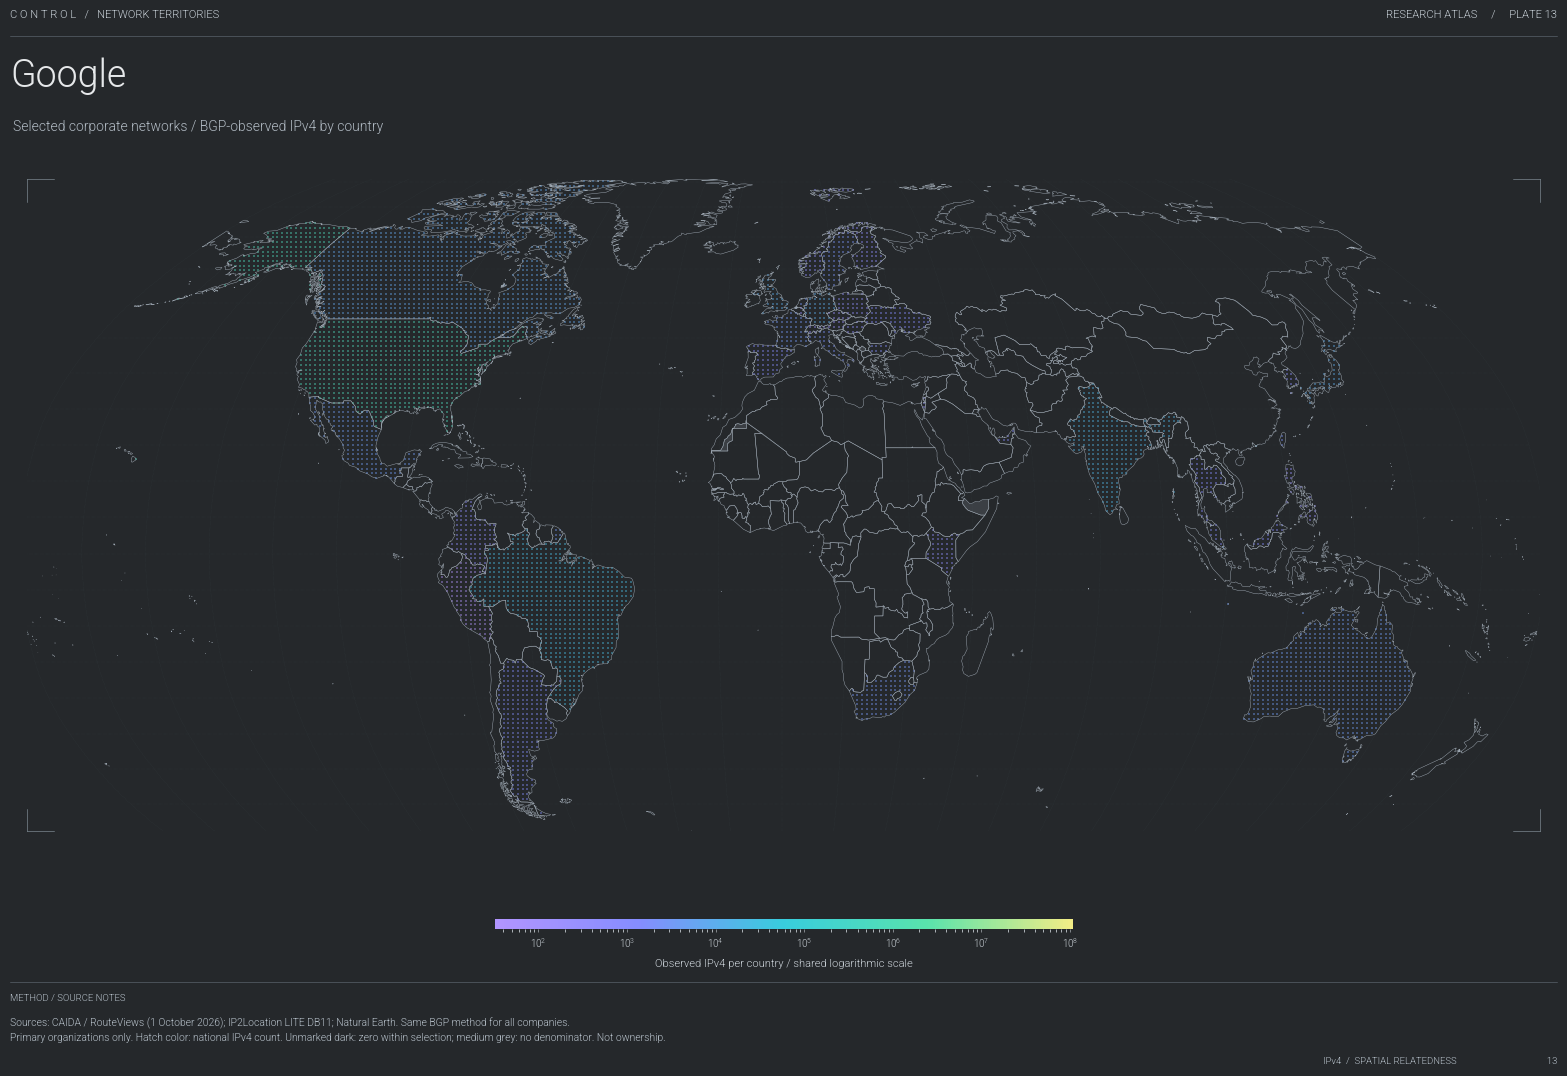

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


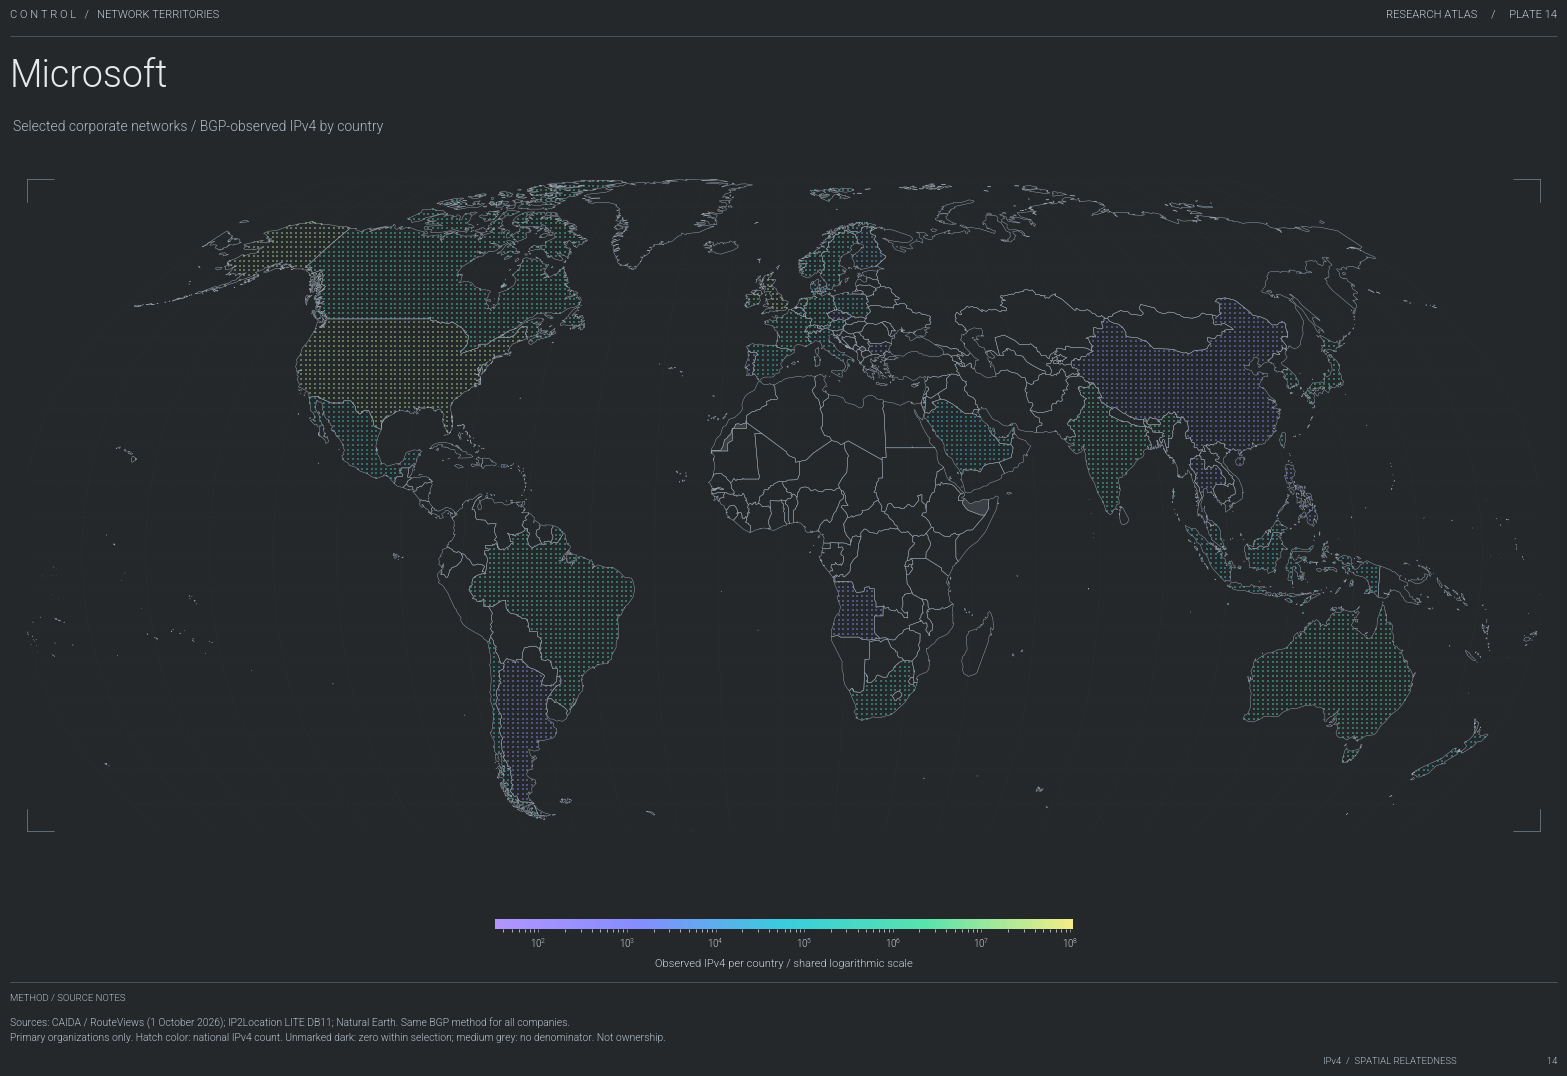

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


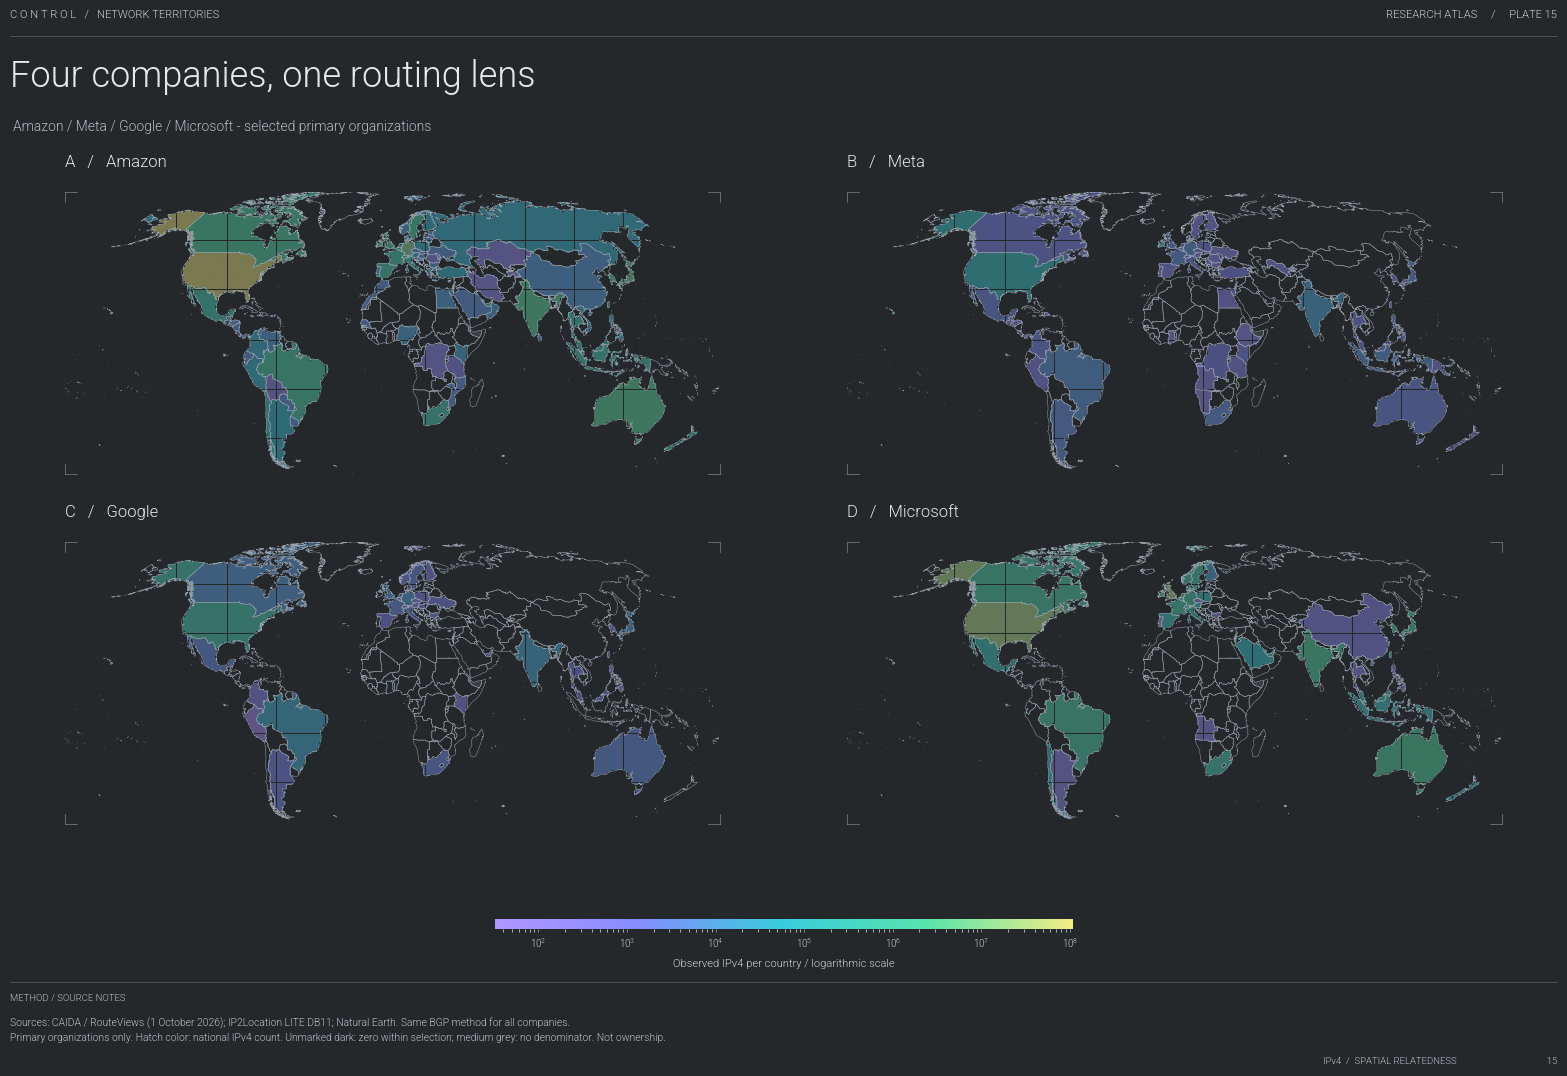

In [16]:
company_tables = {}
for label in COMPANIES:
    subset = company_countries.loc[company_countries["company"].eq(label), ["country_code", "company_ipv4"]]
    table = country_totals.merge(subset, on="country_code", how="left", validate="one_to_one")
    table["company_ipv4"] = table["company_ipv4"].fillna(0)
    company_tables[label] = table
positive_counts = company_countries.loc[company_countries["country_code"].ne("UNKNOWN"), "company_ipv4"]
company_country_norm = LogNorm(positive_counts.min(), positive_counts.max())
company_note = ("Sources: CAIDA / RouteViews (1 October 2026); IP2Location LITE DB11; Natural Earth. Same BGP method for all companies.\n"
                "Primary organizations only. Hatch color: national IPv4 count. Unmarked dark: zero within selection; medium grey: no denominator. Not ownership.")
for label in COMPANIES:
    fig, ax = page(label, "Selected corporate networks / BGP-observed IPv4 by country")
    draw_countries(ax, company_tables[label], "company_ipv4", company_country_norm)
    add_scale(fig, company_country_norm, "Observed IPv4 per country / shared logarithmic scale")
    export_page(fig, "bgp_" + label.lower() + "_locations.pdf", company_note)
country_panel(company_tables, COMPANIES, "company_ipv4", company_country_norm,
              "Four companies, one routing lens", "Amazon / Meta / Google / Microsoft - selected primary organizations",
              "bigtech_bgp_location_maps.pdf", company_note,
              "Observed IPv4 per country / logarithmic scale")

## Chapter 11 / Relative weight
Map each company's share of the national BGP-observed, geolocated IPv4 total. Hatch color uses the same nonlinear percentage scale for all four companies. Unmarked anthracite means zero within the selection, not absence of the company.

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


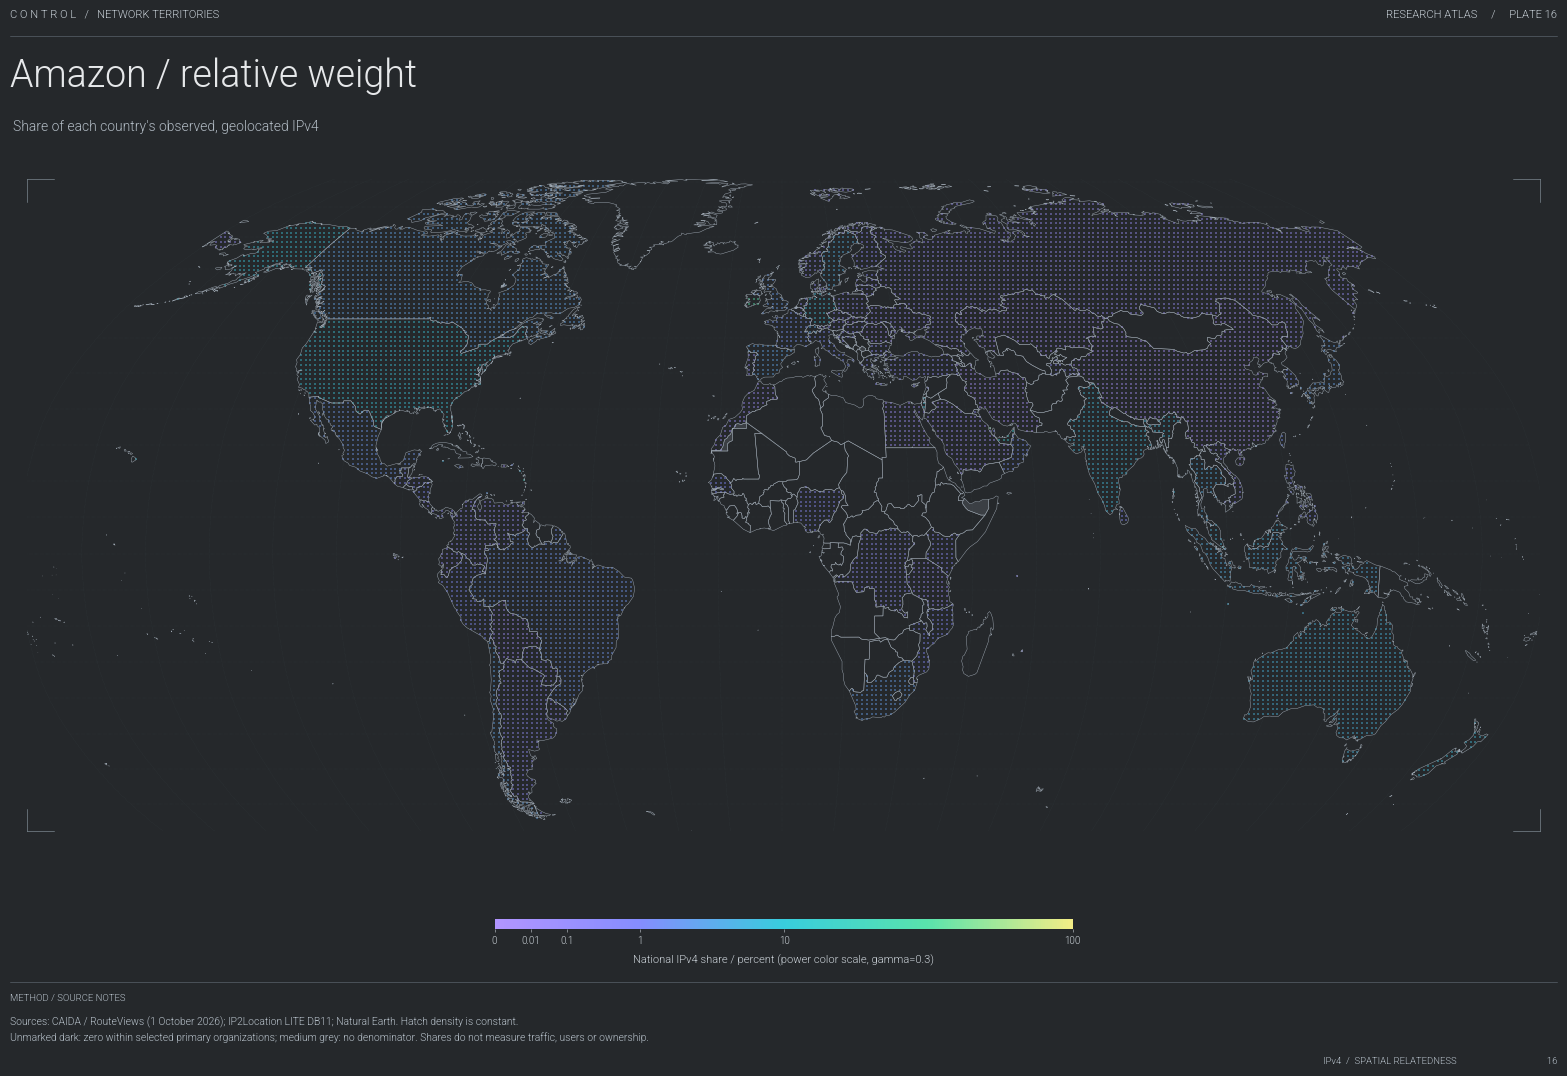

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


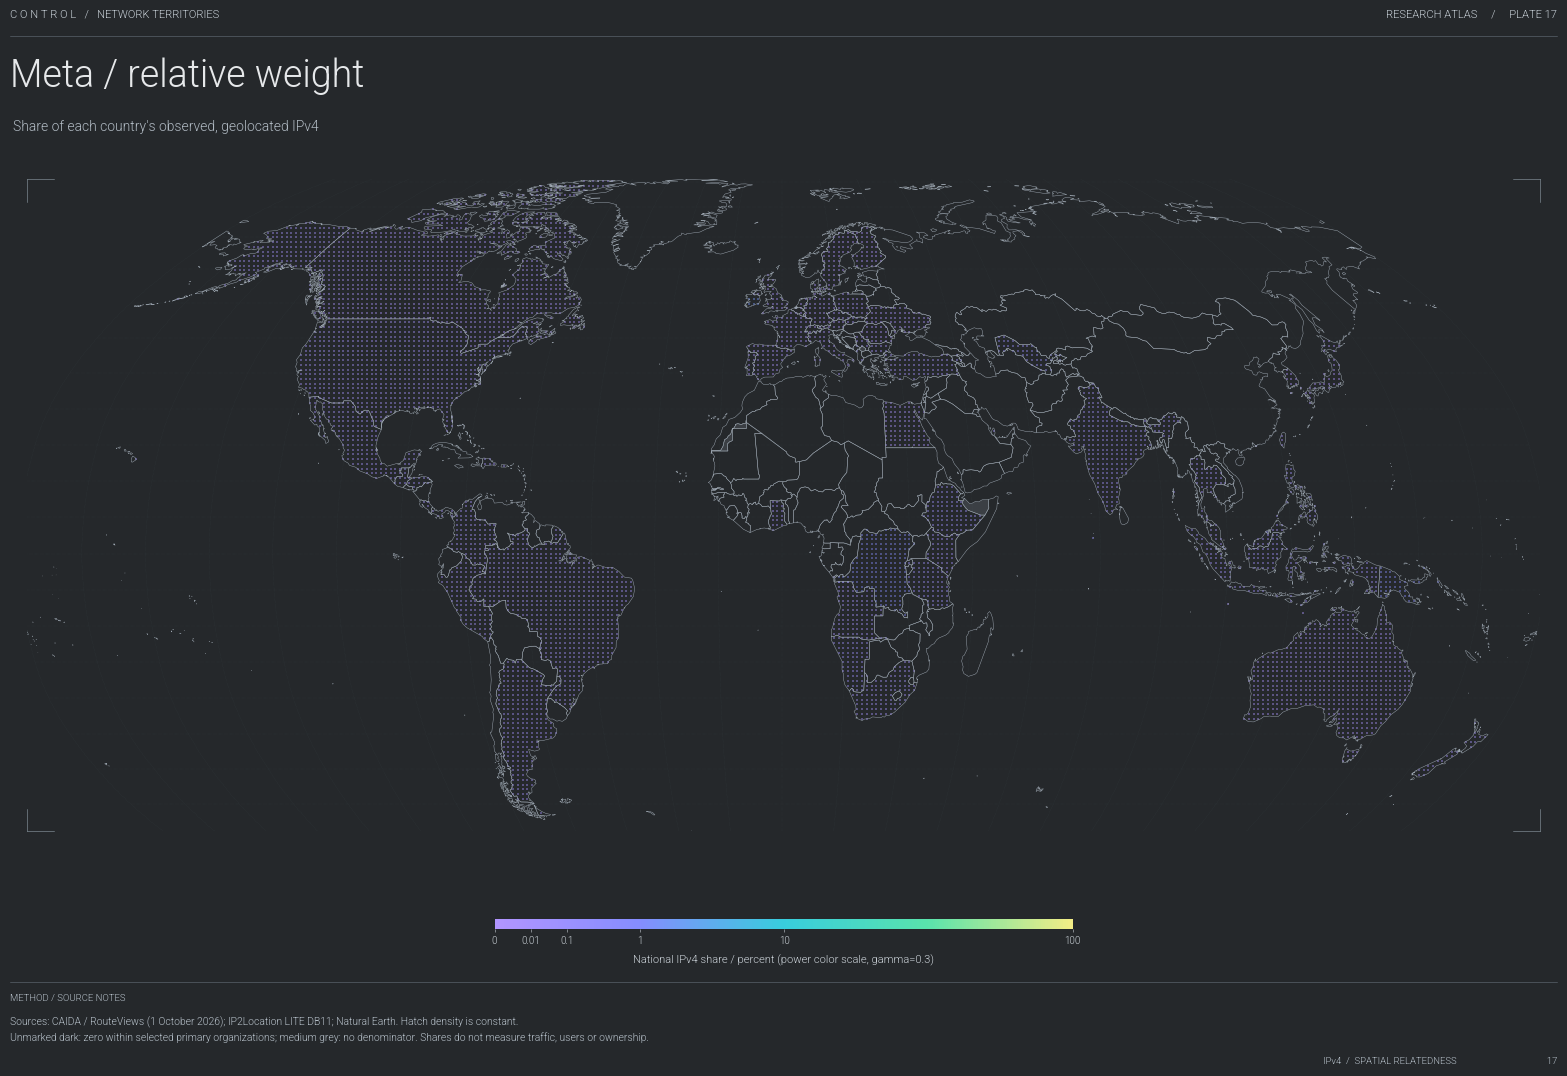

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


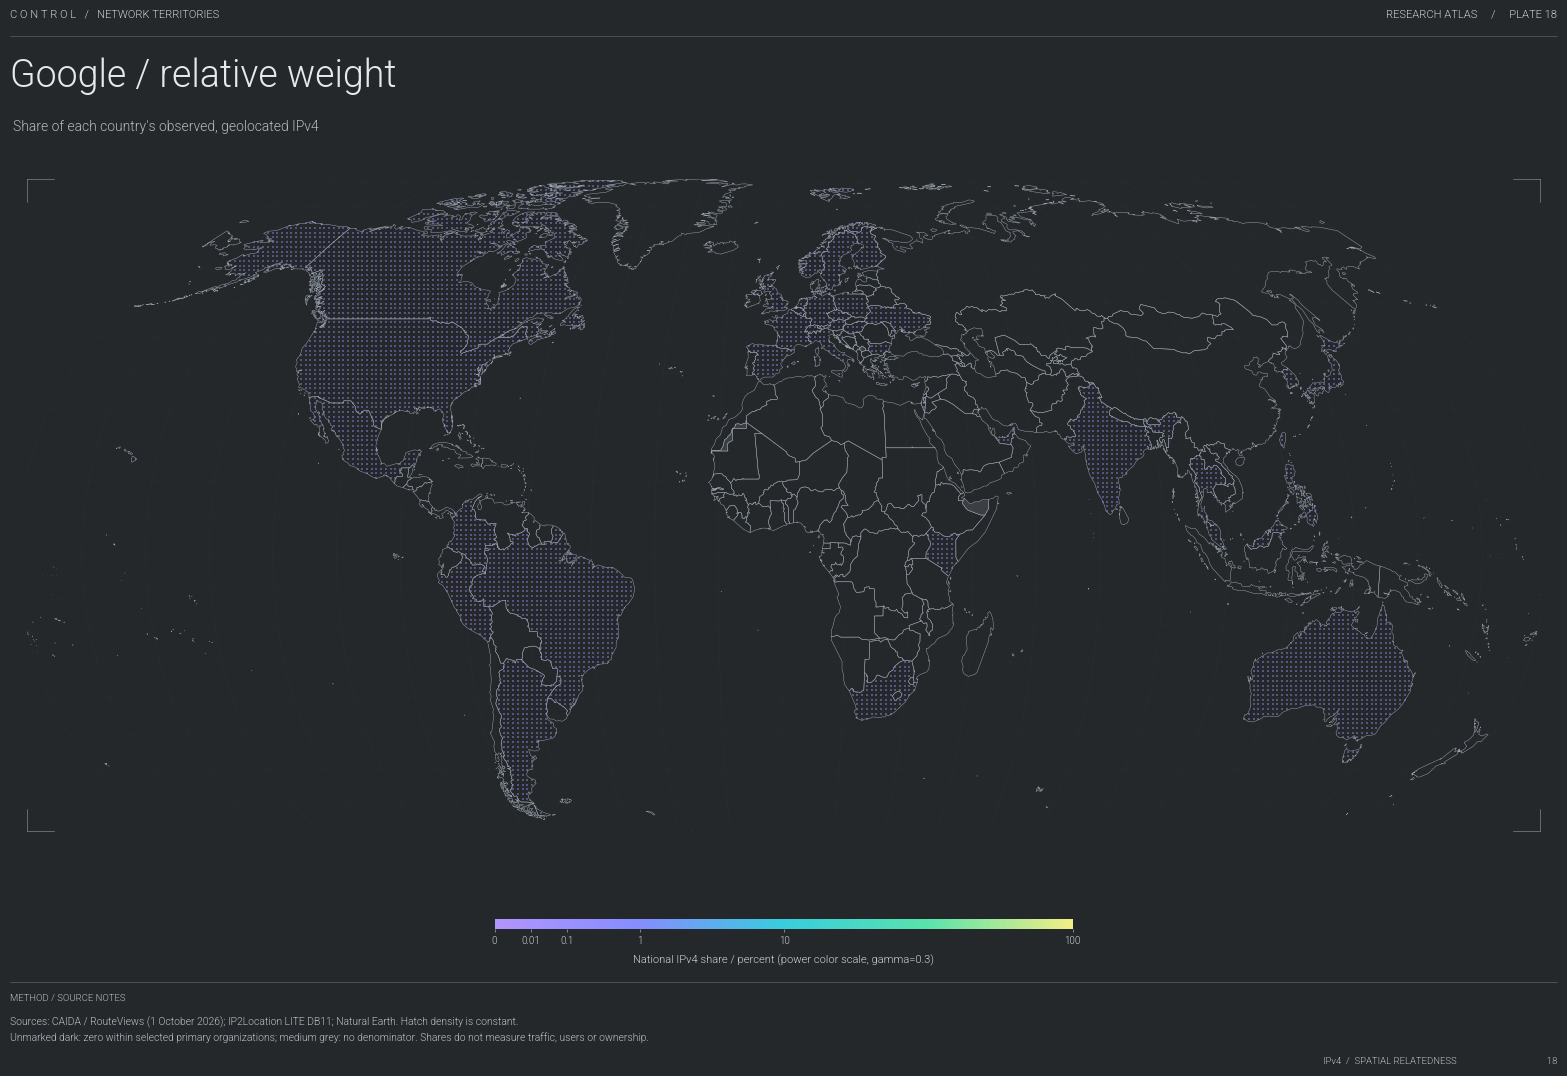

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


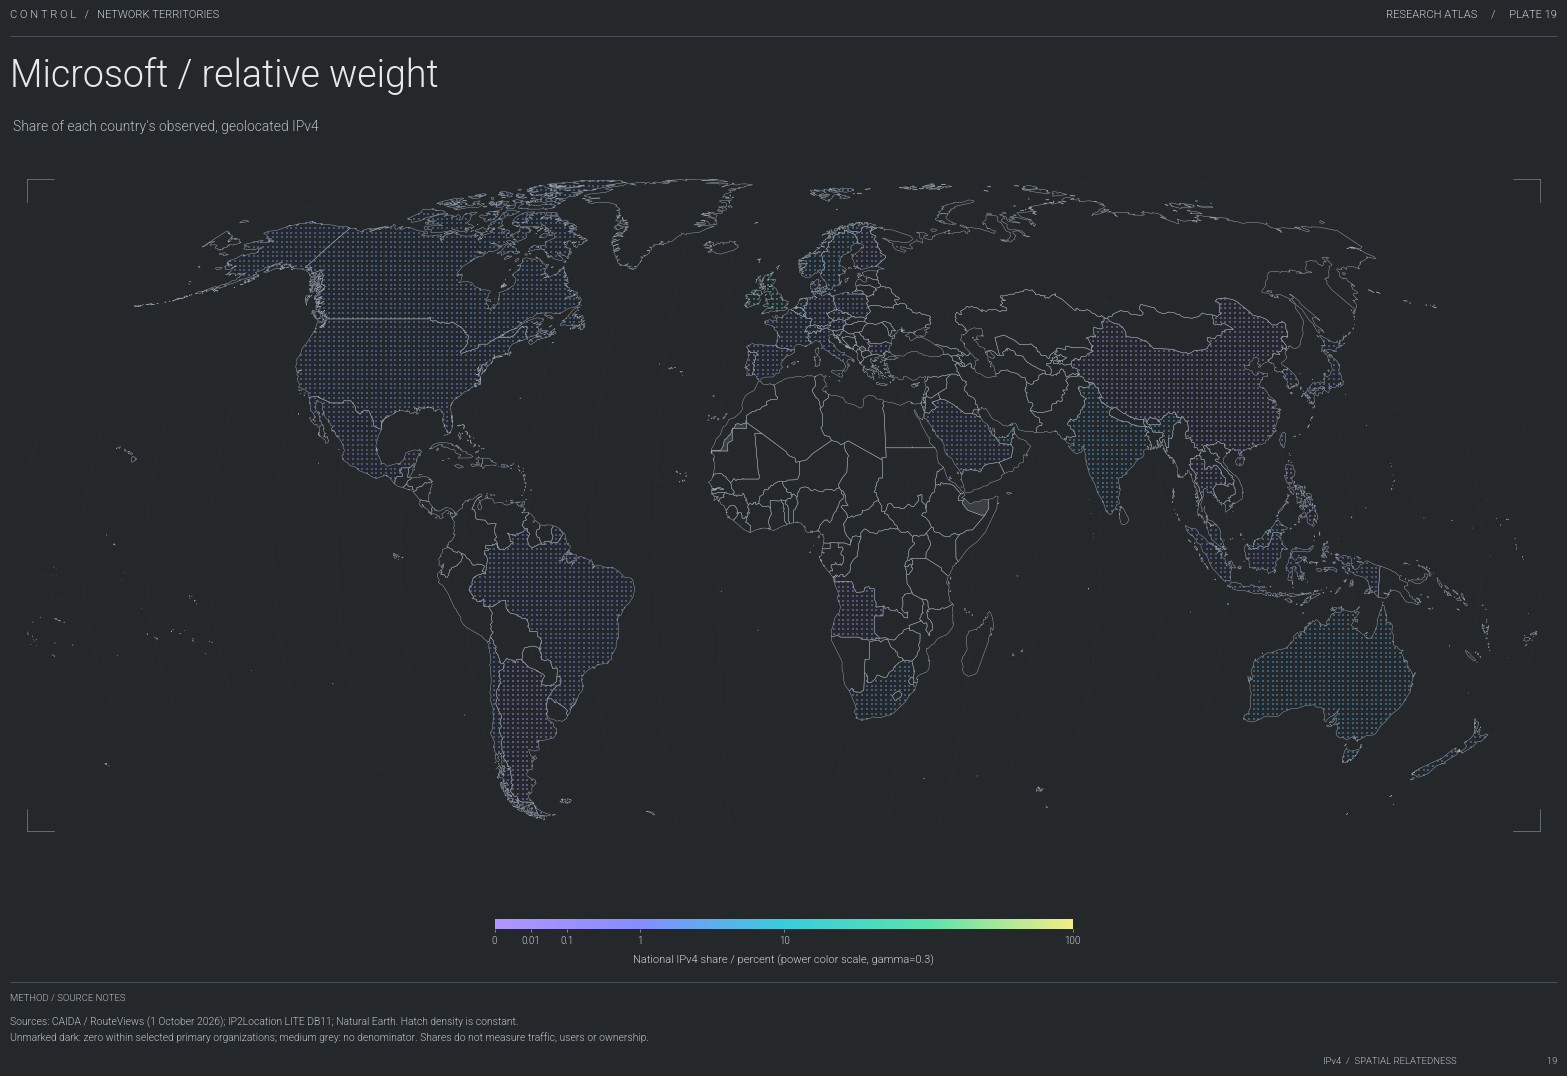

Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


Codes without a matching polygon: ['AQ', 'BQ', 'BV', 'GF', 'GI', 'GP', 'MQ', 'RE', 'SJ', 'TK', 'UM', 'YT']


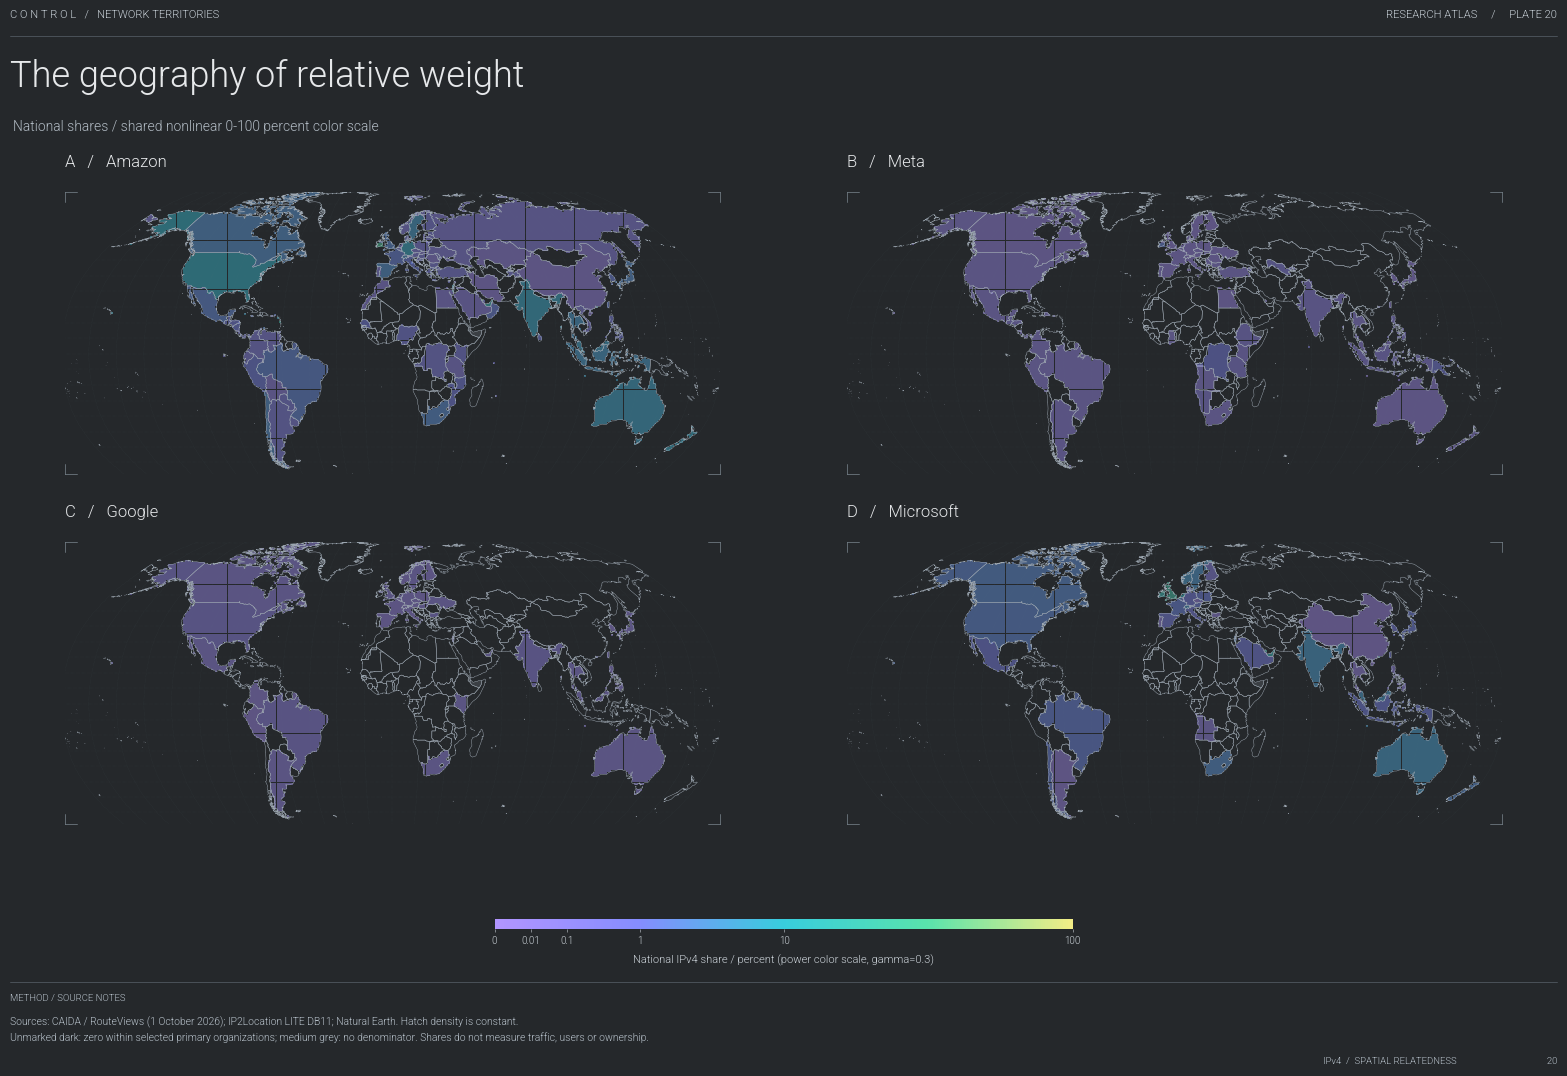

In [17]:
share_tables = {}
for label in COMPANIES:
    table = company_tables[label].copy()
    table["share_pct"] = 100 * table["company_ipv4"] / table["country_observed_ipv4"]
    share_tables[label] = table
share_norm = PowerNorm(gamma=0.3, vmin=0, vmax=100)
share_note = ("Sources: CAIDA / RouteViews (1 October 2026); IP2Location LITE DB11; Natural Earth. Hatch density is constant.\n"
              "Unmarked dark: zero within selected primary organizations; medium grey: no denominator. Shares do not measure traffic, users or ownership.")
for label in COMPANIES:
    fig, ax = page(label + " / relative weight", "Share of each country's observed, geolocated IPv4")
    draw_countries(ax, share_tables[label], "share_pct", share_norm)
    add_scale(fig, share_norm, "National IPv4 share / percent (power color scale, gamma=0.3)")
    export_page(fig, "bgp_" + label.lower() + "_country_share.pdf", share_note)
country_panel(share_tables, COMPANIES, "share_pct", share_norm,
              "The geography of relative weight", "National shares / shared nonlinear 0-100 percent color scale",
              "bigtech_share_by_country.pdf", share_note,
              "National IPv4 share / percent (power color scale, gamma=0.3)")

## Chapter 12 / Export and interpretation
The atlas moves from planetary patterns to national inequalities, administrative distance and corporate concentration. It does not measure traffic, user dependence, legal ownership or personal-data collection. Source dates and missing geolocation affect every interpretation.

In [18]:
atlas.close()
manifest = {"page_size_inches": list(PAGE_SIZE), "background": BACKGROUND,
            "basemap": "Natural Earth boundaries for country maps", "pattern": "constant-density plus-sign lattice", "pdf_files": PDF_FILES,
            "combined_atlas": "Control_Internet_Atlas.pdf",
            "caida_snapshot": "2026-10-01", "geolocation_snapshot": "unverified"}
(OUTPUT_DIR / "atlas_manifest.json").write_text(json.dumps(manifest, indent=2))
print(f"Exported {len(PDF_FILES)} maps and one combined atlas to {OUTPUT_DIR}")

Exported 20 maps and one combined atlas to /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Assignement 03 Spatial Relatedness/output
